# 4-laboratoriya ishi

**Maʼlumotlar:** `input/cars.csv` — 398 ta avtomobil (1970–1982-yillar).

Ish ikki qismdan iborat:
- **I qism. Statistik testlar:** p-qiymatni topish, ANOVA, chi-kvadrat (χ²) testi, boshqa testlar (t-test, Shapiro–Wilk, Spearman, Kruskal–Wallis).
- **II qism. Model qurish** (4-maʼruza): oddiy va koʻp chiziqli regressiya, grafiklar bilan baholash, polinomial regressiya, pipeline, MSE va R², bashorat.

Har bir formulani bir xil tartibda yozdim:
1. **Nima uchun kerak** — formula qaysi savolga javob beradi;
2. **Formula** va undagi **har bir belgi** nimani bildiradi;
3. **Soʻz bilan** — formulani oddiy gap qilib oʻqish;
4. **Qayerdan kelgan** — formula nega aynan shunday;
5. **Hisoblash** — 10 ta mashinada qoʻlda, keyin kod bilan tekshirish.

**Maqsad oʻzgaruvchi — `mpg`** (*miles per gallon*): mashina 1 gallon yoqilgʻida necha mil yuradi. `mpg` qancha katta boʻlsa, mashina shuncha tejamkor. Maʼruzada maqsad oʻzgaruvchi narx (`price`) edi, bizning toʻplamda narx yoʻq, shuning uchun `mpg` bilan ishlayman.

In [23]:
# Kerakli kutubxonalar
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

%matplotlib inline

# Kutubxonalar versiyalari orasidagi texnik ogohlantirishlarni yashiraman
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 4)

# Grafiklar uchun yagona uslub
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "legend.frameon": False,
})

ASOSIY_RANG = "#2a78d6"   # koʻk — haqiqiy maʼlumotlar
URGU_RANG = "#eb6834"     # toʻq sariq — model, bashorat, p-qiymat yuzasi
KULRANG = "#898781"       # yordamchi chiziqlar va fon nuqtalari

NUQTA_USLUB = {"color": ASOSIY_RANG, "alpha": 0.5, "s": 22, "edgecolor": "none"}
CHIZIQ_USLUB = {"color": URGU_RANG, "linewidth": 2}

## 0. Maʼlumotlarni tayyorlash

### 0.1. Maʼlumotlarni yuklash

| Ustun | Maʼnosi |
|---|---|
| `name` | mashina nomi |
| `mpg` | yoqilgʻi tejamkorligi (mil/gallon) — **maqsad oʻzgaruvchi** |
| `cylinders` | silindrlar soni |
| `displacement` | dvigatel hajmi (kub dyuym) |
| `horsepower` | dvigatel quvvati (ot kuchi) |
| `weight` | ogʻirlik (funt; 1 funt ≈ 0.454 kg) |
| `acceleration` | 0 dan 60 mil/soat tezlikkacha necha soniyada yetadi |
| `model_year` | ishlab chiqarilgan yil (70 = 1970) |
| `origin` | ishlab chiqarilgan joy: `usa`, `europe`, `japan` |

In [24]:
df_xom = pd.read_csv("input/cars.csv")   # "xom" — hali tozalanmagan maʼlumot

print("Qatorlar soni:", df_xom.shape[0], "| ustunlar soni:", df_xom.shape[1])
df_xom.head()

Qatorlar soni: 398 | ustunlar soni: 9


,name,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
0,chevrolet chevelle malibu,18.0,8,307.0,130.0,3504,12.0,70,usa
1,buick skylark 320,15.0,8,350.0,165.0,3693,11.5,70,usa
2,plymouth satellite,18.0,8,318.0,150.0,3436,11.0,70,usa
3,amc rebel sst,16.0,8,304.0,150.0,3433,12.0,70,usa
4,ford torino,17.0,8,302.0,140.0,3449,10.5,70,usa


In [25]:
# Har bir ustunda nechta boʻsh qiymat (NaN) bor
df_xom.isna().sum()

name            0
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64

Faqat `horsepower` ustunida 6 ta boʻsh qiymat bor ekan. Model va baʼzi testlar boʻsh qiymat bilan ishlamaydi, shuning uchun bu 6 ta qatorni olib tashladim:

In [26]:
df = df_xom.dropna(subset=["horsepower"]).reset_index(drop=True)
print("Tozalangandan keyin:", len(df), "ta mashina")

Tozalangandan keyin: 392 ta mashina


### 0.2. Qoʻlda hisoblash uchun 10 ta mashina va asosiy sonlar

Formulalarni qoʻlda hisoblash uchun toʻplamdan tasodifiy **10 ta mashina** oldim (`random_state=4` — har safar aynan shu 10 ta mashina chiqishi uchun).
- $x$ — ot kuchi (`horsepower`), $y$ — `mpg`;
- $n$ — mashinalar soni ($n = 10$).

In [27]:
namuna = df_xom.sample(10, random_state=4)[["name", "horsepower", "mpg", "origin"]]
x10 = namuna["horsepower"]   # x
y10 = namuna["mpg"]          # y
n = len(namuna)              # n = 10
namuna

,name,horsepower,mpg,origin
303,datsun 210,65.0,31.8,japan
6,chevrolet impala,220.0,14.0,usa
61,ford pinto runabout,86.0,21.0,usa
310,toyota corolla tercel,60.0,38.1,japan
100,ford maverick,88.0,18.0,usa
272,oldsmobile starfire sx,85.0,23.8,usa
329,honda civic 1500 gl,67.0,44.6,japan
380,nissan stanza xe,88.0,36.0,japan
226,buick skylark,105.0,20.5,usa
328,mercedes-benz 240d,67.0,30.0,europe


Keyingi deyarli barcha formulalarda bir xil sonlar qayta-qayta uchraydi. Ularni shu yerda bir marta hisoblab oldim.

---

#### Oʻrtacha qiymat: $\bar{x}$ va $\bar{y}$

**Nima uchun kerak:** "odatdagi" mashina qanday — bitta son bilan aytish.

**Formula:** $\bar{x} = \dfrac{\sum x}{n}$

- $\bar{x}$ — "x-chiziqcha", $x$ ning oʻrtachasi;
- $\sum$ — "hammasini qoʻsh" degan belgi;
- $n$ — nechta son qoʻshilgani.

**Soʻz bilan:** hamma qiymatlarni qoʻshib, ularning soniga boʻlaman.

**Hisoblash:**

$$\bar{x} = \frac{65 + 220 + 86 + 60 + 88 + 85 + 67 + 88 + 105 + 67}{10} = \frac{931}{10} = 93.1 \text{ ot kuchi}$$

$$\bar{y} = \frac{31.8 + 14.0 + 21.0 + 38.1 + 18.0 + 23.8 + 44.6 + 36.0 + 20.5 + 30.0}{10} = \frac{277.8}{10} = 27.78 \text{ mpg}$$

---

#### Chetlanish: $x - \bar{x}$

**Nima uchun kerak:** har bir mashina oʻrtachadan qancha uzoqligini bilish.

- **Musbat** — mashina oʻrtachadan **yuqori** (masalan, Impala: $220 - 93.1 = +126.9$);
- **manfiy** — oʻrtachadan **past** (masalan, Toyota Tercel: $60 - 93.1 = -33.1$).

Chetlanishlarning yigʻindisi doim **0** boʻladi: oʻrtacha — "muvozanat nuqtasi", yuqoridagilar va pastdagilar bir-birini muvozanatlaydi. Pastdagi jadvalda buni koʻrish mumkin.

---

#### Jadval: har bir mashina uchun hisob

| Mashina | $x$ | $y$ | $x - \bar{x}$ | $y - \bar{y}$ | $(x - \bar{x})(y - \bar{y})$ | $(x - \bar{x})^2$ | $(y - \bar{y})^2$ |
|---|---|---|---|---|---|---|---|
| datsun 210 | 65 | 31.8 | −28.1 | 4.02 | −112.962 | 789.61 | 16.1604 |
| chevrolet impala | 220 | 14.0 | 126.9 | −13.78 | −1748.682 | 16103.61 | 189.8884 |
| ford pinto runabout | 86 | 21.0 | −7.1 | −6.78 | 48.138 | 50.41 | 45.9684 |
| toyota corolla tercel | 60 | 38.1 | −33.1 | 10.32 | −341.592 | 1095.61 | 106.5024 |
| ford maverick | 88 | 18.0 | −5.1 | −9.78 | 49.878 | 26.01 | 95.6484 |
| oldsmobile starfire sx | 85 | 23.8 | −8.1 | −3.98 | 32.238 | 65.61 | 15.8404 |
| honda civic 1500 gl | 67 | 44.6 | −26.1 | 16.82 | −439.002 | 681.21 | 282.9124 |
| nissan stanza xe | 88 | 36.0 | −5.1 | 8.22 | −41.922 | 26.01 | 67.5684 |
| buick skylark | 105 | 20.5 | 11.9 | −7.28 | −86.632 | 141.61 | 52.9984 |
| mercedes-benz 240d | 67 | 30.0 | −26.1 | 2.22 | −57.942 | 681.21 | 4.9284 |
| **Σ** | **931** | **277.8** | **0** | **0** | **−2698.48** | **19660.9** | **878.416** |

Oxirgi uchta ustunning yigʻindilariga qisqa nom berdim: $S_{xy}$, $S_{xx}$, $S_{yy}$.

---

#### $S_{xx}$ va $S_{yy}$ — tarqoqlik

**Formula:** $S_{xx} = \sum (x - \bar{x})^2 = 19660.9$, $\quad S_{yy} = \sum (y - \bar{y})^2 = 878.416$

**Soʻz bilan:** har bir chetlanishni kvadratga koʻtarib, hammasini qoʻshaman.

**Nima uchun kerak:** qiymatlar qanchalik **sochilgan** ekanini bilish. Hamma mashina bir xil boʻlsa — 0, mashinalar juda turlicha boʻlsa — katta son.

**Nega kvadrat:** chetlanishlarni oddiy qoʻshsam, doim 0 chiqadi (musbat va manfiylar bir-birini yoʻqotadi). Kvadrat hamma sonni musbat qiladi.

---

#### $S_{xy}$ — birga oʻzgarish

**Formula:** $S_{xy} = \sum (x - \bar{x})(y - \bar{y}) = -2698.48$

**Soʻz bilan:** har bir mashinaning ikki chetlanishini koʻpaytirib, hammasini qoʻshaman.

**Nima uchun kerak:** $x$ va $y$ **birga qanday oʻzgarishini** bilish.
- Impala: ot kuchi oʻrtachadan **yuqori** (+126.9), `mpg` **past** (−13.78) → koʻpaytma **manfiy** (−1748.7).
- Honda Civic: ot kuchi **past** (−26.1), `mpg` **yuqori** (+16.82) → koʻpaytma yana **manfiy** (−439.0).
- Koʻpchilik koʻpaytmalar manfiy → yigʻindi manfiy → "ot kuchi koʻp boʻlsa, `mpg` kam".

---

#### $r$ — Pearson korrelyatsiya koeffitsiyenti

**Nima uchun kerak:** bogʻliqlik qanchalik **kuchli** ekanini −1 dan +1 gacha boʻlgan bitta son bilan aytish.

**Formula:** $r = \dfrac{S_{xy}}{\sqrt{S_{xx} \cdot S_{yy}}}$

**Soʻz bilan:** birga oʻzgarishni ikkala oʻzgaruvchining tarqoqligiga boʻlaman.

**Qayerdan kelgan:** $S_{xy}$ ning oʻzi "ot kuchi × mpg" birligida, shuning uchun uni boshqa maʼlumotlar bilan solishtirib boʻlmaydi. Uni tarqoqliklarga boʻlsam, birliklar qisqaradi va natija doim **−1 dan +1 gacha** boʻladi:
- $r = -1$ — hamma nuqta pastga tushuvchi toʻgʻri chiziqda;
- $r = 0$ — bogʻliqlik yoʻq;
- $r = +1$ — hamma nuqta yuqoriga koʻtariluvchi toʻgʻri chiziqda.

**Hisoblash:**

$$r = \frac{-2698.48}{\sqrt{19660.9 \cdot 878.416}} = \frac{-2698.48}{4155.77} \approx -0.649$$

---

**Bu sonlar keyin qayerda ishlatiladi:**

| Son | Qiymati | Boʻlimlar |
|---|---|---|
| $n$ | 10 | hamma joyda |
| $\bar{x}$ | 93.1 | 7, 11 |
| $\bar{y}$ | 27.78 | 3, 7 |
| $S_{xy}$ | −2698.48 | 7 |
| $S_{xx}$ | 19660.9 | 2, 5.2, 7, 11 |
| $S_{yy}$ | 878.416 | 2, 3, 12 |
| $r$ | −0.649 | 2, 12 |

Endi xuddi shu hisobni kod bilan bajardim:

In [28]:
x_ort = x10.mean()    # x̄
y_ort = y10.mean()    # ȳ

jadval_0 = pd.DataFrame({
    "x (horsepower)": x10,
    "y (mpg)": y10,
    "x − x̄": x10 - x_ort,
    "y − ȳ": y10 - y_ort,
    "(x − x̄)(y − ȳ)": (x10 - x_ort) * (y10 - y_ort),
    "(x − x̄)²": (x10 - x_ort) ** 2,
    "(y − ȳ)²": (y10 - y_ort) ** 2,
})
jadval_0.index = namuna["name"]
jadval_0.loc["Σ (yigʻindi)"] = jadval_0.sum()
jadval_0.round(4) + 0.0    # + 0.0: "-0.0" oʻrniga "0.0" koʻrinishi uchun

,x (horsepower),y (mpg),x − x̄,y − ȳ,(x − x̄)(y − ȳ),(x − x̄)²,(y − ȳ)²
name,,,,,,,
datsun 210,65.0,31.8,-28.1,4.02,-112.962,789.61,16.1604
chevrolet impala,220.0,14.0,126.9,-13.78,-1748.682,16103.61,189.8884
ford pinto runabout,86.0,21.0,-7.1,-6.78,48.138,50.41,45.9684
toyota corolla tercel,60.0,38.1,-33.1,10.32,-341.592,1095.61,106.5024
ford maverick,88.0,18.0,-5.1,-9.78,49.878,26.01,95.6484
oldsmobile starfire sx,85.0,23.8,-8.1,-3.98,32.238,65.61,15.8404
honda civic 1500 gl,67.0,44.6,-26.1,16.82,-439.002,681.21,282.9124
nissan stanza xe,88.0,36.0,-5.1,8.22,-41.922,26.01,67.5684
buick skylark,105.0,20.5,11.9,-7.28,-86.632,141.61,52.9984


In [29]:
S_xy = ((x10 - x_ort) * (y10 - y_ort)).sum()
S_xx = ((x10 - x_ort) ** 2).sum()
S_yy = ((y10 - y_ort) ** 2).sum()
r = S_xy / np.sqrt(S_xx * S_yy)

print(f"n = {n},   x̄ = {x_ort:.2f},   ȳ = {y_ort:.3f}")
print(f"S_xy = {S_xy:.2f},   S_xx = {S_xx:.1f},   S_yy = {S_yy:.3f}")
print(f"r = S_xy / √(S_xx·S_yy) = {S_xy:.2f} / {np.sqrt(S_xx * S_yy):.2f} = {r:.4f}")
print(f"Tekshiruv (np.corrcoef): r = {np.corrcoef(x10, y10)[0, 1]:.4f}")

n = 10,   x̄ = 93.10,   ȳ = 27.780
S_xy = -2698.48,   S_xx = 19660.9,   S_yy = 878.416
r = S_xy / √(S_xx·S_yy) = -2698.48 / 4155.77 = -0.6493
Tekshiruv (np.corrcoef): r = -0.6493


# I qism. Statistik testlar

## 1. Statistik test nima va p-qiymat nima

**Oddiy misol.** Doʻstim tangani 10 marta tashladi va 10 marta ham gerb tushdi. Tanga halolmi?
1. **Nol gipoteza ($H_0$)** — "hech narsa gʻalati emas": tanga halol.
2. Tanga halol boʻlsa, 10 marta ketma-ket gerb tushish ehtimoli: $\left(\frac{1}{2}\right)^{10} = \frac{1}{1024} \approx 0.001$. Mana shu son — **p-qiymat**.
3. p juda kichik, yaʼni halol tangada bunday holat deyarli boʻlmaydi → $H_0$ ni rad etaman: tanga halol emas.

Har bir statistik test shu sxema boʻyicha ishlaydi:

| Qadam | Nima qilinadi |
|---|---|
| 1. $H_0$ | "hech narsa yoʻq" deb faraz qilaman: bogʻliqlik yoʻq, guruhlar bir xil |
| 2. Test soni | maʼlumotdan bitta son hisoblayman ($t$, $F$, $\chi^2$, $H$). U qanchalik katta boʻlsa, $H_0$ dan shuncha uzoqman |
| 3. p-qiymat | $H_0$ toʻgʻri boʻlsa, shunday katta son tasodifan chiqish ehtimoli |
| 4. Qaror | $p < 0.05$ boʻlsa — "tasodif emas" deyman |

**p-qiymat qayerdan topiladi:** har bir test soni uchun matematiklar tayyor egri chiziq (taqsimot) va jadval chiqarib bergan. U "$H_0$ toʻgʻri boʻlsa, bu son qanday qiymatlar oladi" degan savolga javob beradi. p — shu egri chiziq ostidagi, mening sonimdan "uzoqroq" tarafdagi **yuza**.

**0.05 qayerdan kelgan:** bu tabiat qonuni emas, olimlarning kelishuvi. 1925-yilda ingliz statistigi Ronald Fisher "20 tadan 1 marta (5 %) uchraydigan holatni chegara qilib olish qulay" deb yozgan va bu qoida keng tarqalgan. Maʼnosi: $H_0$ aslida toʻgʻri boʻlsa ham, 100 tadan taxminan 5 marta adashib "bor" deyishga roziman.

Natijani soʻz bilan baholash uchun quyidagi shkaladan foydalanaman:

| p-qiymat | Xulosa |
|---|---|
| p < 0.001 | kuchli dalil |
| 0.001 ≤ p < 0.05 | oʻrtacha dalil |
| 0.05 ≤ p < 0.1 | kuchsiz dalil |
| p ≥ 0.1 | dalil yoʻq |

In [30]:
def p_xulosa(p):
    """p-qiymatni soʻz bilan baholaydi (yuqoridagi shkala)."""
    if p < 0.001:
        return "kuchli dalil"
    if p < 0.05:
        return "oʻrtacha dalil"
    if p < 0.1:
        return "kuchsiz dalil"
    return "dalil yoʻq"

## 2. p-qiymatni topish

**Savol:** 10 ta mashinada ot kuchi va `mpg` orasida $r = -0.649$ chiqdi (0.2-boʻlim). Bu haqiqiy bogʻliqlikmi yoki tasodifan chiqdimi?
- $H_0$: bogʻliqlik yoʻq;
- $H_1$: bogʻliqlik bor.

**Muammo:** $r = -0.649$ "katta"mi? Buni chizgʻichsiz aytib boʻlmaydi. Chizgʻich — **t soni**: bogʻliqlik yoʻq boʻlganda $t$ qanday qiymatlar olishi tayyor jadvalda bor. Shuning uchun $r$ ni $t$ ga aylantiraman, keyin jadvaldan p ni topaman.

### 2.1. t soni

**Nima uchun kerak:** $r$ ni jadvalda qidirsa boʻladigan songa aylantirish.

**Formula:** $t = \dfrac{r \cdot \sqrt{n-2}}{\sqrt{1-r^2}}$

- $r$ — korrelyatsiya (−0.649);
- $n$ — mashinalar soni (10);
- $1 - r^2$ — nuqtalarning chiziq bilan tushuntirilmagan qismi (12-boʻlimda batafsil).

**Soʻz bilan:** "bogʻliqlik kuchi × maʼlumot miqdori, boʻlingan tushuntirilmagan qismga". Shuning uchun:
- $r$ katta boʻlsa → $t$ katta;
- mashinalar koʻp boʻlsa → $t$ katta (koʻp maʼlumotdagi natija ishonchliroq);
- nuqtalar chiziqqa yaqin boʻlsa ($1 - r^2$ kichik) → $t$ katta.

**Qayerdan kelgan.** $t$ aslida **"signal / shovqin"**:

$$t = \frac{\text{signal}}{\text{shovqin}} = \frac{b_1}{SE}$$

- **Signal — $b_1$** (chiziqning qiyaligi): ot kuchi 1 ga oshsa, `mpg` qanchaga oʻzgaradi. Bogʻliqlik yoʻq boʻlsa, chiziq tekis, yaʼni $b_1 = 0$ boʻlardi. Bizda $b_1 = \dfrac{S_{xy}}{S_{xx}} = \dfrac{-2698.48}{19660.9} = -0.137$ (formulasini 7-boʻlimda tushuntiraman).
- **Shovqin — SE** (standart xato): boshqa 10 ta mashina olsam, qiyalik taxminan qanchaga oʻzgarib ketardi. U ikki narsaga bogʻliq:
  - nuqtalar chiziqdan qanchalik uzoq: $s = \sqrt{\dfrac{SSE}{n-2}} = \sqrt{\dfrac{508.05}{8}} = 7.97$ mpg. Bu yerda $SSE = S_{yy}(1 - r^2) = 878.416 \cdot 0.5784 = 508.05$ — chiziq tushuntira olmagan qism;
  - ot kuchi qanchalik keng oraliqda: $\sqrt{S_{xx}} = \sqrt{19660.9} = 140.2$. Oraliq keng boʻlsa, chiziq qimirlamaydi — uzun chizgʻichni ikki uchidan ushlagandek.
  - $SE = \dfrac{s}{\sqrt{S_{xx}}} = \dfrac{7.97}{140.2} = 0.0568$.
- **Natija:** $t = \dfrac{-0.137}{0.0568} = -2.415$, yaʼni qiyalik noldan **2.4 ta "shovqin"** uzoqda.

$b_1$ va SE ni $r$ orqali yozib qisqartirsa, yuqoridagi formula chiqadi. Shuning uchun amalda $b_1$ va SE ni hisoblamasdan, $t$ ni toʻgʻridan-toʻgʻri $r$ dan topaman. Ikkala yoʻl bilan hisoblab, bir xil chiqishini kodda tekshirdim.

**Hisoblash (formula bilan):**

$$t = \frac{-0.649 \cdot \sqrt{8}}{\sqrt{1 - 0.4216}} = \frac{-0.649 \cdot 2.828}{0.7605} = \frac{-1.836}{0.7605} \approx -2.415$$

### 2.2. df — erkinlik darajasi

**Nima uchun kerak:** t-jadvalning qaysi qatoriga qarashni aytadi.

**Formula:** $df = n - 2 = 10 - 2 = 8$

**Qayerdan kelgan.** Oddiy misol: 3 ta sonning oʻrtachasi 10 ga teng. Ikkitasi 8 va 12 boʻlsa, uchinchisi **majburan** 10 boʻladi — 3 ta sondan faqat 2 tasi "erkin". Bizda chiziq chizish uchun maʼlumotdan **2 ta son** ($b_0$ va $b_1$) hisoblandi. Shuning uchun 10 ta nuqtadan 8 tasi "erkin" qoldi.

### 2.3. p-qiymat

**Nima uchun kerak:** yakuniy javob — tasodifmi yoki yoʻqmi.

**Formula:** $p = 2 \cdot P(T \geq |t|)$

- $T$ — bogʻliqlik yoʻq boʻlganda tasodifan chiqadigan $t$;
- $P(T \geq 2.415)$ — t-egri chizigʻi ostida 2.415 dan **oʻngdagi yuza**;
- 2 — ikki tomon uchun.

**Soʻz bilan:** "bogʻliqlik yoʻq boʻlsa, $|t|$ 2.415 dan katta chiqish ehtimoli".

**Qayerdan kelgan:**
- t-egri chizigʻini 1908-yilda William Gosset ("Student" taxallusi bilan) matematik yoʻl bilan hisoblab chiqqan. t-jadval va `scipy.stats.t` aynan shu egri chiziqdan foydalanadi.
- **Nega 2 ga koʻpaytiraman:** bogʻliqlik manfiy ham, musbat ham boʻlishi mumkin edi. Ikki tomondagi "gʻalati" qiymatlar ham hisobga olinadi: chap dumda ($t \leq -2.415$) 0.021, oʻng dumda ($t \geq 2.415$) yana 0.021. Jami $p = 0.042$.
- **Nega oddiy normal egri chiziq emas:** shovqinni (SE) ham atigi 10 ta mashinadan taxmin qildim, u ham aniq emas. Shu sabab katta $t$ lar koʻproq uchraydi, t-egri chizigʻining dumlari normalnikidan qalinroq. Mashinalar koʻpaygan sari t-egri chizigʻi normal egri chiziqqa aylanadi.

**Jadval bilan:** t-jadvalda $df = 8$ qatorida **2.306** (p = 0.05) va **2.896** (p = 0.02) turibdi. Mening $|t| = 2.415$ shu ikkisining orasida, demak $0.02 < p < 0.05$.

Hammasini kod bilan tekshirdim:

In [31]:
# 1-yoʻl: signal / shovqin (S_xy, S_xx, S_yy, r, n — 0.2-boʻlimdan)
b1_signal = S_xy / S_xx                         # signal: qiyalik
SSE_10 = S_yy * (1 - r ** 2)                    # chiziq tushuntira olmagan qism
s_10 = np.sqrt(SSE_10 / (n - 2))                # nuqtalar chiziqdan oʻrtacha qancha uzoq
SE_b1 = s_10 / np.sqrt(S_xx)                    # shovqin: qiyalikning standart xatosi

print(f"signal  b1 = S_xy / S_xx = {b1_signal:.4f}")
print(f"SSE = S_yy·(1 − r²) = {SSE_10:.2f},   s = √(SSE/(n−2)) = {s_10:.2f},   √S_xx = {np.sqrt(S_xx):.1f}")
print(f"shovqin SE = s / √S_xx = {SE_b1:.4f}")
print(f"t = signal / shovqin = {b1_signal / SE_b1:.4f}")

# 2-yoʻl: toʻgʻridan-toʻgʻri r dan
t_stat = r * np.sqrt(n - 2) / np.sqrt(1 - r ** 2)
print(f"t = r·√(n−2) / √(1−r²) = {t_stat:.4f}")

signal  b1 = S_xy / S_xx = -0.1373
SSE = S_yy·(1 − r²) = 508.05,   s = √(SSE/(n−2)) = 7.97,   √S_xx = 140.2
shovqin SE = s / √S_xx = 0.0568
t = signal / shovqin = -2.4150
t = r·√(n−2) / √(1−r²) = -2.4150


In [32]:
# p-qiymat: t-egri chizigʻi ostidagi yuza. sf — "oʻngdagi yuza" degani
ong_dum = stats.t.sf(abs(t_stat), df=n - 2)
p_formula = 2 * ong_dum

r_scipy, p_scipy = stats.pearsonr(x10, y10)          # tayyor funksiya

print(f"df = {n - 2},   oʻng dumdagi yuza = {ong_dum:.4f},   p = 2 × {ong_dum:.4f} = {p_formula:.4f}")
print(f"stats.pearsonr: p = {p_scipy:.4f}")
print(f"Jadvaldagi chegaralar (df = 8): {stats.t.ppf(0.975, 8):.3f} (p = 0.05),  {stats.t.ppf(0.99, 8):.3f} (p = 0.02)")

df = 8,   oʻng dumdagi yuza = 0.0211,   p = 2 × 0.0211 = 0.0422
stats.pearsonr: p = 0.0422
Jadvaldagi chegaralar (df = 8): 2.306 (p = 0.05),  2.896 (p = 0.02)


### 2.4. p-qiymatni tajriba bilan topish (permutatsiya)

Bu usulda hech qanday jadval kerak emas — p ning maʼnosi eng aniq koʻrinadi.

**Gʻoya:** agar bogʻliqlik yoʻq boʻlsa, qaysi `mpg` qaysi mashinaga tegishli ekani muhim emas. Shuning uchun:
1. `mpg` qiymatlarini qurʼa tashlagandek aralashtiraman va $r$ ni hisoblayman;
2. buni 10 000 marta takrorlayman;
3. necha marta $|r| \geq 0.649$ chiqqanini sanayman.

**Formula:** $p \approx \dfrac{|r| \geq 0.649 \text{ chiqqan holatlar soni}}{10\,000}$

**Soʻz bilan:** "bogʻliqlik yoʻq boʻlganda, mening natijamdek kuchli $r$ qanchalik tez-tez chiqadi".

In [33]:
rng = np.random.default_rng(0)        # natija har safar bir xil chiqishi uchun
B = 10_000
r_aralash = np.array([np.corrcoef(x10, rng.permutation(y10.to_numpy()))[0, 1] for _ in range(B)])
p_perm = (np.abs(r_aralash) >= abs(r)).mean()

print(f"{B} marta aralashtirdim. |r| ≥ {abs(r):.3f} chiqqan holatlar: {(np.abs(r_aralash) >= abs(r)).sum()} ta  ->  p ≈ {p_perm:.4f}")

10000 marta aralashtirdim. |r| ≥ 0.649 chiqqan holatlar: 202 ta  ->  p ≈ 0.0202


Ikkala usulni grafikda koʻrsatdim: p-qiymat — toʻq sariq rangdagi yuza (ulush).

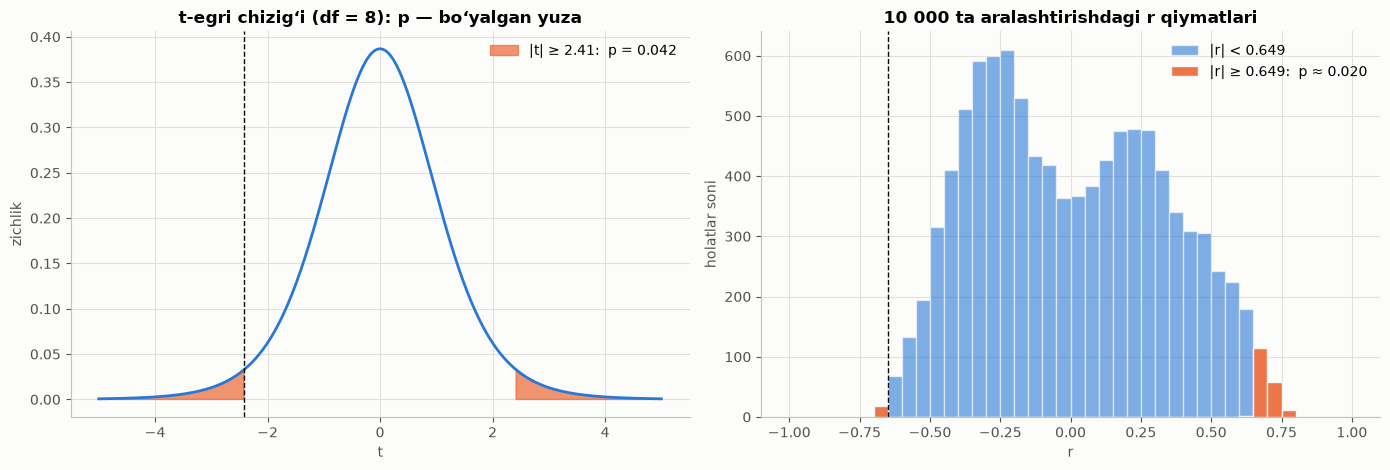

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Chapda: t-egri chizigʻi (df = 8), p — ikki dumdagi yuza
ax = axes[0]
t_oqi = np.linspace(-5, 5, 400)
zichlik = stats.t.pdf(t_oqi, df=n - 2)
ax.plot(t_oqi, zichlik, color=ASOSIY_RANG, linewidth=2)
ax.fill_between(t_oqi, zichlik, where=np.abs(t_oqi) >= abs(t_stat), color=URGU_RANG, alpha=0.7,
                label=f"|t| ≥ {abs(t_stat):.2f}:  p = {p_formula:.3f}")
ax.axvline(t_stat, color="#0b0b0b", linestyle="--", linewidth=1)
ax.set_title(f"t-egri chizigʻi (df = {n - 2}): p — boʻyalgan yuza")
ax.set_xlabel("t")
ax.set_ylabel("zichlik")
ax.legend(loc="upper right")

# Oʻngda: aralashtirishlardagi r lar, p — toʻq sariq ustunlar ulushi
ax = axes[1]
chegaralar = np.linspace(-1, 1, 41)
ax.hist(r_aralash[np.abs(r_aralash) < abs(r)], bins=chegaralar, color=ASOSIY_RANG, alpha=0.6,
        edgecolor="#fcfcfb", label=f"|r| < {abs(r):.3f}")
ax.hist(r_aralash[np.abs(r_aralash) >= abs(r)], bins=chegaralar, color=URGU_RANG, alpha=0.9,
        edgecolor="#fcfcfb", label=f"|r| ≥ {abs(r):.3f}:  p ≈ {p_perm:.3f}")
ax.axvline(r, color="#0b0b0b", linestyle="--", linewidth=1)
ax.set_title("10 000 ta aralashtirishdagi r qiymatlari")
ax.set_xlabel("r")
ax.set_ylabel("holatlar soni")
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

**Kuzatish:**
- Formula, jadval va `pearsonr` bir xil natija berdi: $t = -2.415$, $p = 0.042$.
- Aralashtirish usuli $p \approx 0.020$ berdi. Farqning sababi: t-formula maʼlumotni "qoʻngʻiroq shaklida" (normal) deb faraz qiladi, mening 10 ta mashinamda esa Impala (220 ot kuchi) qolganlardan juda ajralib turadi. Aralashtirish usuli bunday farazga muhtoj emas. Oʻngdagi gistogramma ikki tepalikli chiqqani ham Impala taʼsiri.
- Ikkala usulda ham $p < 0.05$ → xulosa bir xil: **oʻrtacha dalil**, bogʻliqlik tasodif emas.

Butun toʻplamda (392 ta mashina) ham tekshirdim:

In [35]:
r_toliq, p_toliq = stats.pearsonr(df["horsepower"], df["mpg"])
print(f"392 ta mashina: r = {r_toliq:.4f}, p = {p_toliq:.2e}  ->  {p_xulosa(p_toliq)}")

392 ta mashina: r = -0.7784, p = 7.03e-81  ->  kuchli dalil


**Kuzatish:** $r = -0.778$, $p \approx 7 \cdot 10^{-81}$ (amalda 0). Mashinalar koʻp boʻlgani uchun $t$ formulasidagi $\sqrt{n-2}$ juda katta boʻldi va p deyarli nolga tushdi.

---

## 3. ANOVA (dispersiya tahlili)

**Nima uchun kerak:** 3 va undan koʻp guruhning **oʻrtacha** qiymatlari farq qiladimi, shuni bilish. Mening savolim: AQSH, Yevropa va Yaponiya mashinalarining oʻrtacha `mpg` i farq qiladimi?
- $H_0$: uchala guruh oʻrtachasi bir xil;
- $H_1$: kamida bittasi farq qiladi.

**Gʻoya.** Mashinalarning `mpg` lari turlicha. Bu turlichalikning ikki sababi bor:
1. mashina **qaysi guruhdan** ekani — **guruhlar orasidagi** farq ($SS_B$);
2. bir guruh ichida ham mashinalar har xil — **guruh ichidagi** farq ($SS_W$).

$$\underbrace{SS_T}_{\text{umumiy}} = \underbrace{SS_B}_{\text{orasidagi}} + \underbrace{SS_W}_{\text{ichidagi}}$$

### 3.1. Formulalar

**$SS_B$ — guruhlar orasidagi farq:** $\;SS_B = \sum n_j (\bar{y}_j - \bar{y})^2$
- $\bar{y}_j$ — $j$-guruhning oʻrtachasi, $\bar{y}$ — hamma mashinalarning oʻrtachasi, $n_j$ — guruhdagi mashinalar soni.
- **Soʻz bilan:** har bir guruh oʻrtachasi umumiy oʻrtachadan qancha uzoq — kvadratga koʻtarib, guruh hajmiga koʻpaytiraman.

**$SS_W$ — guruh ichidagi farq:** $\;SS_W = \sum (y - \bar{y}_j)^2$
- **Soʻz bilan:** har bir mashina **oʻz guruhining** oʻrtachasidan qancha uzoq — kvadratlarini qoʻshaman.

**$F$ — natija:** $\;F = \dfrac{SS_B / (k-1)}{SS_W / (N-k)}$
- $k$ — guruhlar soni, $N$ — mashinalar soni.
- **Soʻz bilan:** "guruhlar orasidagi farq / guruh ichidagi farq".
- $k - 1$ va $N - k$ ga boʻlish — 2.2-boʻlimdagi erkinlik darajasi gʻoyasi: $k$ ta guruh oʻrtachasi umumiy oʻrtacha bilan bogʻlangan → $k - 1$ ta erkin; $N$ ta mashinadan $k$ ta oʻrtacha hisoblandi → $N - k$ ta erkin.

**Qayerdan kelgan.**
- Guruhlar aslida bir xil boʻlsa, ular orasidagi farq ham guruh ichidagi farqdek tasodifiy boʻladi → $F \approx 1$.
- Guruhlar haqiqatan farq qilsa, orasidagi farq ancha katta boʻladi → $F$ katta.
- $F$ qanchalik katta boʻlishi mumkinligini **F-jadval** aytadi (t-jadval kabi tayyor jadval).

**Nega shunchaki oʻrtachalarni solishtirmayman?** Misol: ikki sinfning oʻrtacha bahosi 4.0 va 4.2. Agar har bir sinf ichida baholar 2 dan 5 gacha sochilgan boʻlsa, 0.2 farq tasodif boʻlishi mumkin. Agar har bir sinfda hamma deyarli bir xil baho olgan boʻlsa, 0.2 farq ham muhim. $F$ aynan shuni hisobga oladi.

### 3.2. Qoʻlda hisoblash (10 ta mashina)

**1-qadam. Guruh oʻrtachalari** (har bir guruh qiymatlarini qoʻshib, soniga boʻldim):

| Guruh | `mpg` qiymatlari | $n_j$ | $\bar{y}_j$ |
|---|---|---|---|
| japan | 31.8, 38.1, 44.6, 36.0 | 4 | $150.5 / 4 = 37.625$ |
| usa | 14.0, 21.0, 18.0, 23.8, 20.5 | 5 | $97.3 / 5 = 19.46$ |
| europe | 30.0 | 1 | 30.0 |

Umumiy oʻrtacha $\bar{y} = 27.78$ (0.2-boʻlim).

**2-qadam. Guruhlar orasidagi farq:**

$$SS_B = 4 \cdot (37.625 - 27.78)^2 + 5 \cdot (19.46 - 27.78)^2 + 1 \cdot (30.0 - 27.78)^2 = 4 \cdot 96.924 + 5 \cdot 69.222 + 4.928 = 738.74$$

**3-qadam. Guruh ichidagi farq** (har bir mashina oʻz guruhi oʻrtachasidan):
- japan: $(31.8 - 37.625)^2 + (38.1 - 37.625)^2 + (44.6 - 37.625)^2 + (36.0 - 37.625)^2 = 33.931 + 0.226 + 48.651 + 2.641 = 85.447$
- usa: $(14.0 - 19.46)^2 + (21.0 - 19.46)^2 + (18.0 - 19.46)^2 + (23.8 - 19.46)^2 + (20.5 - 19.46)^2 = 29.812 + 2.372 + 2.132 + 18.836 + 1.082 = 54.232$
- europe: bitta mashina, $(30 - 30)^2 = 0$

$$SS_W = 85.447 + 54.232 + 0 = 139.68$$

**Tekshiruv:** $SS_B + SS_W = 738.74 + 139.68 = 878.42$. Bu 0.2-boʻlimdagi $S_{yy} = 878.416$ ning oʻzi — umumiy tarqoqlik haqiqatan ikki boʻlakka boʻlindi ✓

**4-qadam.**

$$F = \frac{738.74 / (3 - 1)}{139.68 / (10 - 3)} = \frac{369.37}{19.954} \approx 18.51$$

F-jadvalda $(2, 7)$ uchun chegara ($p = 0.05$) — 4.74. Mening $F = 18.51$ undan ancha katta → $p < 0.05$.

(Namunada Yevropa mashinasi bitta. Formulalar ishlaydi, lekin bitta mashina boʻyicha xulosa chiqarib boʻlmaydi — shuning uchun pastda butun toʻplamda ham tekshirdim.)

In [36]:
guruhlar = namuna.groupby("origin")["mpg"]
print(guruhlar.agg(["count", "sum", "mean"]))            # n_j, yigʻindi va guruh oʻrtachasi

SS_B = (guruhlar.count() * (guruhlar.mean() - y_ort) ** 2).sum()   # guruhlar orasida (ȳ — 0.2-boʻlimdan)
SS_W = ((y10 - guruhlar.transform("mean")) ** 2).sum()             # guruh ichida
k, N = guruhlar.ngroups, len(namuna)
F = (SS_B / (k - 1)) / (SS_W / (N - k))
p_anova = stats.f.sf(F, k - 1, N - k)          # F-egri chizigʻi ostidagi oʻngdagi yuza

print(f"\nSS_B = {SS_B:.3f},  SS_W = {SS_W:.3f},  SS_B + SS_W = {SS_B + SS_W:.3f}  (S_yy = {S_yy:.3f})")
print(f"Formula bilan:   F = {F:.4f},  p = {p_anova:.5f}")
print("stats.f_oneway: ", stats.f_oneway(*[qiymatlar for _, qiymatlar in guruhlar]))
print(f"F-jadvaldagi chegara (2, 7), p = 0.05: {stats.f.ppf(0.95, k - 1, N - k):.2f}")

        count    sum    mean
origin                      
europe      1   30.0  30.000
japan       4  150.5  37.625
usa         5   97.3  19.460

SS_B = 738.736,  SS_W = 139.680,  SS_B + SS_W = 878.416  (S_yy = 878.416)
Formula bilan:   F = 18.5108,  p = 0.00160
stats.f_oneway:  F_onewayResult(statistic=np.float64(18.510788984782998), pvalue=np.float64(0.001603295299275614))
F-jadvaldagi chegara (2, 7), p = 0.05: 4.74


Butun toʻplamda (392 ta mashina) ham tekshirdim. Qoʻshimcha ravishda **tushuntirilgan ulush** $SS_B / SS_T$ ni hisobladim — `mpg` dagi farqlarning necha foizi `origin` ga bogʻliq:

In [37]:
guruhlar_t = df.groupby("origin")["mpg"]
F_t, p_t = stats.f_oneway(*[qiymatlar for _, qiymatlar in guruhlar_t])
ulush = (guruhlar_t.count() * (guruhlar_t.mean() - df["mpg"].mean()) ** 2).sum() / ((df["mpg"] - df["mpg"].mean()) ** 2).sum()

print(guruhlar_t.agg(["count", "mean"]).round(2))
print(f"\nF = {F_t:.2f},  p = {p_t:.2e}  ->  {p_xulosa(p_t)};  tushuntirilgan ulush = {100 * ulush:.1f} %")

        count   mean
origin              
europe     68  27.60
japan      79  30.45
usa       245  20.03

F = 96.60,  p = 8.67e-35  ->  kuchli dalil;  tushuntirilgan ulush = 33.2 %


**Kuzatish:**
- 10 ta mashinada: $F = 18.51$, $p = 0.0016$ → oʻrtacha dalil. Qoʻlda hisoblaganim scipy bilan bir xil chiqdi.
- 392 ta mashinada: $F \approx 96.6$, $p \approx 9 \cdot 10^{-35}$ → **kuchli dalil**: ishlab chiqarilgan joy `mpg` ga taʼsir qiladi. `mpg` dagi farqlarning ~33 % i `origin` bilan bogʻliq.

---

## 4. Chi-kvadrat (χ²) testi

**Nima uchun kerak:** **ikkala oʻzgaruvchi ham toifa** (son emas) boʻlganda, ular bogʻliqmi — shuni bilish. ANOVA da bitta oʻzgaruvchi son edi (`mpg`), bu yerda esa ikkalasi ham toifa.

Savolim: **mashina AQSHda yoki import (Yevropa/Yaponiya) ekani bilan silindrlar soni (4 ta yoki koʻproq) bogʻliqmi?**
- $H_0$: bogʻliq emas;
- $H_1$: bogʻliq.

Avval jadval tuzdim — har bir katakda nechta mashina bor:

In [38]:
kelib_chiqish = pd.Series(np.where(df["origin"] == "usa", "AQSH", "import"), name="kelib chiqish")
silindr = pd.Series(np.where(df["cylinders"] == 4, "4 silindr", "4 dan koʻp"), name="silindr")

jadval = pd.crosstab(kelib_chiqish, silindr)[["4 silindr", "4 dan koʻp"]]
pd.crosstab(kelib_chiqish, silindr, margins=True, margins_name="Jami")[["4 silindr", "4 dan koʻp", "Jami"]]

silindr,4 silindr,4 dan koʻp,Jami
kelib chiqish,,,
AQSH,69,176,245
import,130,17,147
Jami,199,193,392


### 4.1. Formulalar

**$O$ — kuzatilgan son:** jadvaldagi haqiqiy son (masalan, AQSHdagi 4 silindrli mashinalar — 69 ta).

**$E$ — kutilgan son:** agar bogʻliqlik **yoʻq** boʻlsa, katakda nechta mashina boʻlishi kerak edi.

$$E = \frac{\text{qator jami} \times \text{ustun jami}}{N}$$

**$E$ qayerdan kelgan — misol bilan.**
- Hamma mashinalarning $199 / 392 = 50.8\,\%$ i 4 silindrli.
- Agar kelib chiqish silindrga taʼsir qilmasa, AQSHning 245 ta mashinasining ham 50.8 % i 4 silindrli boʻlishi kerak: $245 \times 0.508 = 124.4$ ta.
- Bu aynan formula: $E = \dfrac{245 \times 199}{392} = 124.4$.
- Haqiqatda esa AQSHda 4 silindrli mashinalar atigi **69 ta**. Kutilgandan ancha kam!

**$\chi^2$ — natija:**

$$\chi^2 = \sum \frac{(O - E)^2}{E}$$

**Soʻz bilan:** har bir katakda "haqiqat kutilgandan qancha farq qildi" — kvadratga koʻtarib, kutilgan songa boʻlib, hammasini qoʻshaman.
- $O - E$ — farq;
- **kvadrat** — manfiy va musbat farqlar bir-birini yoʻqotmasligi uchun;
- **$E$ ga boʻlish** — farqni kutilgan songa nisbatan oʻlchash uchun: 100 ta kutganda 10 ta farq kichik, 5 ta kutganda 10 ta farq juda katta.

**$df$ — erkinlik darajasi:** $df = (\text{qatorlar} - 1) \times (\text{ustunlar} - 1) = 1 \times 1 = 1$.
Qayerdan: jami sonlar maʼlum boʻlsa, 2×2 jadvalda bitta katakni bilish yetarli, qolgan 3 tasi ayirish bilan topiladi. Masalan, AQSHda 4 silindrli 69 ta boʻlsa, AQSHdagi qolganlari $245 - 69 = 176$ ta.

**p-qiymat:** χ²-jadvaldan (yoki χ²-egri chizigʻidan) topiladi. $df = 1$ uchun chegara ($p = 0.05$) — **3.84**.

**Shart:** har bir katakda $E \geq 5$ boʻlishi kerak, aks holda test notoʻgʻri ishlaydi.

### 4.2. Qoʻlda hisoblash

**1-qadam. Kutilgan sonlar $E$:**

| | 4 silindr | 4 dan koʻp |
|---|---|---|
| AQSH | $245 \times 199 / 392 = 124.375$ | $245 \times 193 / 392 = 120.625$ |
| import | $147 \times 199 / 392 = 74.625$ | $147 \times 193 / 392 = 72.375$ |

Hamma $E \geq 5$ → shart bajarilgan.

**2-qadam. Har bir katak uchun $(O - E)^2 / E$.** 2×2 jadvalda hamma kataklarda farq bir xil chiqdi: $|69 - 124.375| = 55.375$, kvadrati $55.375^2 = 3066.39$.

| | 4 silindr | 4 dan koʻp |
|---|---|---|
| AQSH | $3066.39 / 124.375 = 24.654$ | $3066.39 / 120.625 = 25.421$ |
| import | $3066.39 / 74.625 = 41.091$ | $3066.39 / 72.375 = 42.368$ |

**3-qadam.**

$$\chi^2 = 24.654 + 25.421 + 41.091 + 42.368 = 133.53$$

Chegara 3.84 edi, mening $\chi^2 = 133.5$ undan juda katta → $p$ juda kichik.

In [39]:
O = jadval.to_numpy()                       # kuzatilgan sonlar
qator_jami = O.sum(axis=1)                  # [245, 147]
ustun_jami = O.sum(axis=0)                  # [199, 193]
N_jami = O.sum()                            # 392

E = np.outer(qator_jami, ustun_jami) / N_jami      # E = qator jami × ustun jami / N
chi2_qolda = ((O - E) ** 2 / E).sum()
df_chi = (O.shape[0] - 1) * (O.shape[1] - 1)
p_chi_qolda = stats.chi2.sf(chi2_qolda, df_chi)

print("Kutilgan sonlar E:\n", pd.DataFrame(E, index=jadval.index, columns=jadval.columns).round(3))
print(f"\nQoʻlda (formula):       χ² = {chi2_qolda:.3f},  df = {df_chi},  p = {p_chi_qolda:.2e}")

# correction=False — scipy 2×2 jadvalda odatda kichik tuzatish (Yates) qiladi; qoʻlda hisobim bilan solishtirish uchun oʻchirdim
chi2_s, p_s, df_s, E_s = stats.chi2_contingency(jadval, correction=False)
print(f"stats.chi2_contingency: χ² = {chi2_s:.3f},  df = {df_s},  p = {p_s:.2e}")
print(f"χ²-jadvaldagi chegara (df = 1, p = 0.05): {stats.chi2.ppf(0.95, 1):.2f}")

Kutilgan sonlar E:
 silindr        4 silindr  4 dan koʻp
kelib chiqish                       
AQSH             124.375     120.625
import            74.625      72.375

Qoʻlda (formula):       χ² = 133.534,  df = 1,  p = 6.91e-31
stats.chi2_contingency: χ² = 133.534,  df = 1,  p = 6.91e-31
χ²-jadvaldagi chegara (df = 1, p = 0.05): 3.84


**Kuzatish:**
- AQSH mashinalarining atigi 28 % i ($69/245$) 4 silindrli, import mashinalarning esa 88 % i ($130/147$).
- $\chi^2 = 133.5$, $p \approx 7 \cdot 10^{-31}$ → **kuchli dalil**: kelib chiqish va silindrlar soni bogʻliq.

### 4.3. Kattaroq jadval: `origin` × `mpg` toifasi
`mpg` ni 3 ta teng toifaga ajratdim (har birida ~131 ta mashina): **past** (≤ 18.7), **oʻrta** (18.7–26.9), **yuqori** (> 26.9). Keyin ularni 3 ta `origin` bilan tekshirdim. Bu yerda $df = (3-1) \times (3-1) = 4$.

In [40]:
mpg_toifa = pd.qcut(df["mpg"], 3, labels=["past", "oʻrta", "yuqori"]).rename("mpg toifasi")
jadval3 = pd.crosstab(df["origin"], mpg_toifa)

chi2_3, p_3, df_3, E_3 = stats.chi2_contingency(jadval3)
print(jadval3)
print(f"\nχ² = {chi2_3:.2f},  df = {df_3},  p = {p_3:.2e}  ->  {p_xulosa(p_3)}")
print(f"Eng kichik kutilgan son E = {E_3.min():.1f} (≥ 5 boʻlishi kerak)")

mpg toifasi  past  oʻrta  yuqori
origin                          
europe          4     31      33
japan           1     21      57
usa           126     78      41

χ² = 128.49,  df = 4,  p = 8.18e-27  ->  kuchli dalil
Eng kichik kutilgan son E = 22.6 (≥ 5 boʻlishi kerak)


**Kuzatish:** AQSH mashinalarining 126 tasi "past" toifada (kutilgani ~82 ta), Yaponiya mashinalarining 57 tasi "yuqori" toifada (kutilgani ~26 ta). $\chi^2 = 128.5$, $p \approx 8 \cdot 10^{-27}$ → kelib chiqish va tejamkorlik **kuchli bogʻliq**. Eng kichik $E = 22.6$, shart bajarilgan.

---

## 5. Boshqa testlar

### 5.1. t-test: ikki guruhni solishtirish

**Nima uchun kerak:** **ikkita** guruh (masalan, Yaponiya va AQSH mashinalari) oʻrtachasi farq qiladimi, shuni bilish.

**Formula:**

$$t = \frac{\bar{x}_1 - \bar{x}_2}{s_p \cdot \sqrt{\frac{1}{n_1} + \frac{1}{n_2}}}, \qquad df = n_1 + n_2 - 2$$

- $\bar{x}_1 - \bar{x}_2$ — ikki guruh oʻrtachalarining farqi (**signal**);
- $s_p$ — ikki guruh ichidagi tarqoqlikning oʻrtachasi;
- $\sqrt{\frac{1}{n_1} + \frac{1}{n_2}}$ — guruhlar kichik boʻlsa katta, katta boʻlsa kichik;
- maxrajning hammasi — **shovqin**: oʻrtachalar farqi tasodifan qanchalik qimirlashi mumkin.

**Soʻz bilan:** "oʻrtachalar farqi / shovqin" — 2-boʻlimdagi signal/shovqin gʻoyasining oʻzi.

**Qayerdan kelgan:**
- Guruh ichida mashinalar qanchalik turlicha boʻlsa ($s_p$ katta), oʻrtachalar farqi tasodifan shuncha katta chiqishi mumkin → shovqin katta.
- Guruhlarda mashina koʻp boʻlsa, oʻrtacha aniqroq → shovqin kichik.
- $df = n_1 + n_2 - 2$, chunki 2 ta oʻrtacha hisoblandi (2.2-boʻlimdagi gʻoya).

**Guruh dispersiyasi $s^2$ va $s_p^2$:**

$$s^2 = \frac{\sum (x - \bar{x})^2}{n - 1}, \qquad s_p^2 = \frac{(n_1 - 1) s_1^2 + (n_2 - 1) s_2^2}{n_1 + n_2 - 2}$$

$s^2$ — bitta guruhning tarqoqligi ($n - 1$ ga boʻlinadi — bitta oʻrtacha hisoblangan). $s_p^2$ — ikki guruh tarqoqligining birlashtirilgan oʻrtachasi.

**Qoʻlda hisoblash (10 ta mashina: japan va usa).** Kvadratlar yigʻindisini 3.2-boʻlimda hisoblaganman:
- japan: $n_1 = 4$, $\bar{x}_1 = 37.625$, $\sum (x - \bar{x}_1)^2 = 85.447$ → $s_1^2 = 85.447 / 3 = 28.482$
- usa: $n_2 = 5$, $\bar{x}_2 = 19.46$, $\sum (x - \bar{x}_2)^2 = 54.232$ → $s_2^2 = 54.232 / 4 = 13.558$

$$s_p^2 = \frac{3 \cdot 28.482 + 4 \cdot 13.558}{4 + 5 - 2} = \frac{139.68}{7} = 19.954, \qquad s_p = \sqrt{19.954} = 4.467$$

$$t = \frac{37.625 - 19.46}{4.467 \cdot \sqrt{\frac{1}{4} + \frac{1}{5}}} = \frac{18.165}{4.467 \cdot 0.6708} = \frac{18.165}{2.9966} \approx 6.06, \qquad df = 7$$

t-jadvalda $df = 7$ uchun chegara 2.365; $6.06 > 2.365$ → $p < 0.05$.

**ANOVA bilan aloqasi:** guruhlar ikkita boʻlsa, ANOVA ning $F$ i $t^2$ ga teng: $6.06^2 \approx 36.7$. Yaʼni t-test — ANOVA ning 2 guruhli holati.

In [41]:
japan10 = namuna.loc[namuna["origin"] == "japan", "mpg"]
usa10 = namuna.loc[namuna["origin"] == "usa", "mpg"]

n1, n2 = len(japan10), len(usa10)
s1_2, s2_2 = japan10.var(), usa10.var()                       # .var() — n−1 ga boʻladi
s_p2 = ((n1 - 1) * s1_2 + (n2 - 1) * s2_2) / (n1 + n2 - 2)
t_qolda = (japan10.mean() - usa10.mean()) / np.sqrt(s_p2 * (1 / n1 + 1 / n2))
p_t_qolda = 2 * stats.t.sf(abs(t_qolda), n1 + n2 - 2)

print(f"s1² = {s1_2:.3f},  s2² = {s2_2:.3f},  s_p² = {s_p2:.3f}")
print(f"Qoʻlda:          t = {t_qolda:.4f},  p = {p_t_qolda:.5f}")
print("stats.ttest_ind:", stats.ttest_ind(japan10, usa10))
print(f"t² = {t_qolda ** 2:.3f},  ANOVA (2 guruh) F = {stats.f_oneway(japan10, usa10).statistic:.3f}")

s1² = 28.483,  s2² = 13.558,  s_p² = 19.954
Qoʻlda:          t = 6.0619,  p = 0.00051
stats.ttest_ind: TtestResult(statistic=np.float64(6.061942735205104), pvalue=np.float64(0.0005098918409316915), df=np.float64(7.0))
t² = 36.747,  ANOVA (2 guruh) F = 36.747


Butun toʻplamda ham tekshirdim. **Welch t-testi** — guruhlar tarqoqligi har xil boʻlganda ishlatiladigan varianti: unda $s_p$ oʻrniga har bir guruh oʻz tarqoqligi bilan olinadi.

In [42]:
japan = df.loc[df["origin"] == "japan", "mpg"]
usa = df.loc[df["origin"] == "usa", "mpg"]

print(f"japan: n = {len(japan)}, oʻrtacha = {japan.mean():.2f}")
print(f"usa:   n = {len(usa)}, oʻrtacha = {usa.mean():.2f}")
for nom, natija in [("Student", stats.ttest_ind(japan, usa)),
                    ("Welch  ", stats.ttest_ind(japan, usa, equal_var=False))]:
    print(f"{nom}: t = {natija.statistic:.2f},  p = {natija.pvalue:.2e}  ->  {p_xulosa(natija.pvalue)}")

japan: n = 79, oʻrtacha = 30.45
usa:   n = 245, oʻrtacha = 20.03
Student: t = 12.66,  p = 4.17e-30  ->  kuchli dalil
Welch  : t = 13.03,  p = 7.51e-26  ->  kuchli dalil


**Kuzatish:**
- 10 ta mashinada $t = 6.06$, $p = 0.0005$. Qoʻlda hisoblaganim scipy bilan mos keldi, $t^2 = 36.75$ ANOVA ning $F$ iga teng chiqdi.
- 392 ta mashinada: Yaponiya oʻrtacha 30.45 mpg, AQSH — 20.03 mpg, $t = 12.66$, $p \approx 10^{-30}$ → **kuchli dalil**.

### 5.2. Shapiro–Wilk testi: maʼlumot "qoʻngʻiroq shaklida"mi?

**Nima uchun kerak:** t-test, ANOVA va Pearson p-qiymati maʼlumot **normal taqsimlangan** (gistogrammasi qoʻngʻiroq shaklida) degan farazga tayanadi. Shapiro–Wilk shu farazni tekshiradi.
- $H_0$: maʼlumot normal; $p < 0.05$ boʻlsa — normal emas.

**Formula:**

$$W = \frac{\left(\sum a_i \cdot (\text{kattadan } i\text{-qiymat} - \text{kichikdan } i\text{-qiymat})\right)^2}{S_{xx}}$$

- **Surat:** qiymatlarni tartiblayman, eng kattasidan eng kichigini, ikkinchi kattasidan ikkinchi kichigini va hokazo ayiraman. Har bir farqni $a_i$ koeffitsiyentiga koʻpaytirib qoʻshaman va kvadratga koʻtaraman. Bu — "normal taqsimot boʻlsa, tarqoqlik qanday boʻlishi kerak" degan baho.
- **Maxraj:** oddiy tarqoqlik $S_{xx}$ (0.2-boʻlim).
- $a_i$ — tayyor **Shapiro–Wilk jadvalidan** olinadi (S. Shapiro va M. Wilk, 1965). Xuddi t-jadval kabi.

**Soʻz bilan:** "normal taqsimotga xos tarqoqlik / haqiqiy tarqoqlik".

**Qayerdan kelgan:** maʼlumot haqiqatan normal boʻlsa, ikkala baho deyarli teng boʻladi va $W \approx 1$. Normal boʻlmasa (masalan, bitta juda katta qiymat boʻlsa), maxraj kattalashadi va $W$ kichrayadi.

**Qoʻlda hisoblash (10 ta mashinaning ot kuchi).** Tartiblangan qator: $60,\ 65,\ 67,\ 67,\ 85,\ 86,\ 88,\ 88,\ 105,\ 220$. Jadvaldan ($n = 10$): $a_1 = 0.5739$, $a_2 = 0.3291$, $a_3 = 0.2141$, $a_4 = 0.1224$, $a_5 = 0.0399$.

| $i$ | Farq | $a_i \times$ farq |
|---|---|---|
| 1 | $220 - 60 = 160$ | $0.5739 \times 160 = 91.824$ |
| 2 | $105 - 65 = 40$ | $0.3291 \times 40 = 13.164$ |
| 3 | $88 - 67 = 21$ | $0.2141 \times 21 = 4.496$ |
| 4 | $88 - 67 = 21$ | $0.1224 \times 21 = 2.570$ |
| 5 | $86 - 85 = 1$ | $0.0399 \times 1 = 0.040$ |
| | **Σ** | **112.094** |

$$W = \frac{112.094^2}{19660.9} = \frac{12565.1}{19660.9} \approx 0.639$$

$W$ 1 dan ancha uzoq → ot kuchi normal taqsimlanmagan (sababi — 220 ot kuchli Impala).

In [43]:
a = [0.5739, 0.3291, 0.2141, 0.1224, 0.0399]           # Shapiro–Wilk jadvali, n = 10
x_tartib = np.sort(x10.to_numpy())                     # kichikdan kattaga tartiblangan
print("Tartiblangan qator:", x_tartib)

farqlar = x_tartib[::-1][:5] - x_tartib[:5]           # eng kattasi − eng kichigi, ...
yigindi_a = (np.array(a) * farqlar).sum()
print("Farqlar:", farqlar, "  Σ a × farq =", round(yigindi_a, 3))

W_qolda = yigindi_a ** 2 / S_xx                        # maxraj — 0.2-boʻlimdagi S_xx
print(f"Qoʻlda (jadval koeffitsiyentlari): W = {W_qolda:.4f}")
print("stats.shapiro:                  ", stats.shapiro(x10))

Tartiblangan qator: [ 60.  65.  67.  67.  85.  86.  88.  88. 105. 220.]
Farqlar: [160.  40.  21.  21.   1.]   Σ a × farq = 112.094
Qoʻlda (jadval koeffitsiyentlari): W = 0.6391
stats.shapiro:                   ShapiroResult(statistic=np.float64(0.6388515688773062), pvalue=np.float64(0.0001612328941990886))


scipy $a_i$ ni jadvaldan emas, taqribiy formuladan hisoblaydi, shuning uchun $W$ ning 4-xonasida kichik farq bor.

**Q-Q grafik** — normallikni koʻz bilan tekshirish: X oʻqida — "maʼlumot normal boʻlsa, qiymatlar qanday boʻlishi kerak edi", Y oʻqida — haqiqiy qiymatlar. Nuqtalar toʻgʻri chiziq ustida yotsa — maʼlumot normal.

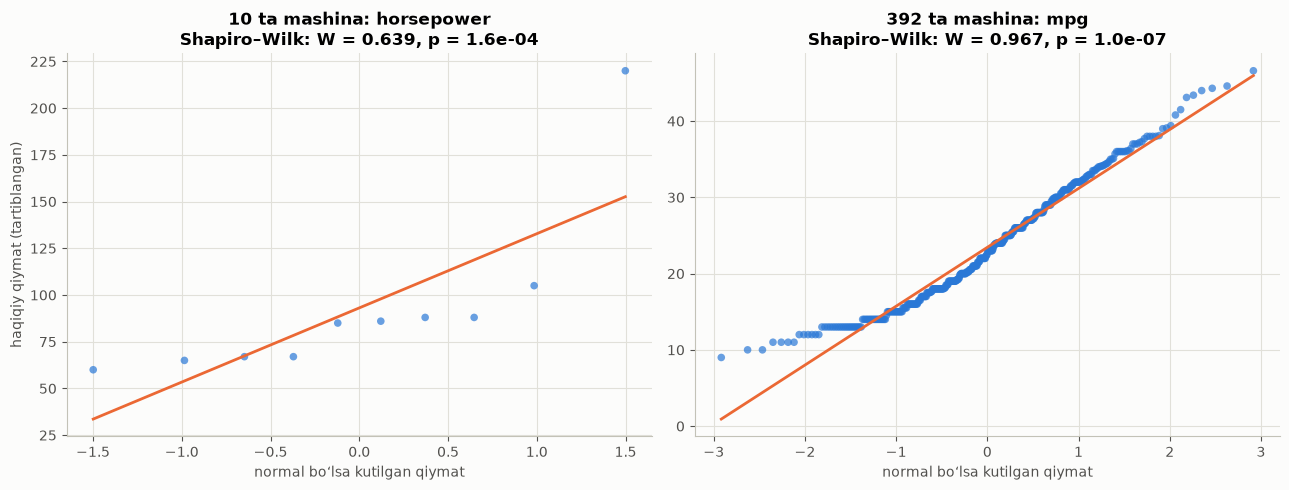

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, qiymatlar, sarlavha in [(axes[0], x10, "10 ta mashina: horsepower"),
                                (axes[1], df["mpg"], "392 ta mashina: mpg")]:
    (nazariy, haqiqiy), (qiyalik, kesish, _) = stats.probplot(qiymatlar, dist="norm")
    ax.scatter(nazariy, haqiqiy, **{**NUQTA_USLUB, "alpha": 0.7, "s": 30})
    ax.plot(nazariy, qiyalik * nazariy + kesish, **CHIZIQ_USLUB)
    W, p_sh = stats.shapiro(qiymatlar)
    ax.set_title(f"{sarlavha}\nShapiro–Wilk: W = {W:.3f}, p = {p_sh:.1e}")
    ax.set_xlabel("normal boʻlsa kutilgan qiymat")
axes[0].set_ylabel("haqiqiy qiymat (tartiblangan)")
plt.tight_layout()
plt.show()

In [45]:
# Har bir origin guruhidagi mpg normalmi? (ANOVA va t-test farazi)
for nom, qiymatlar in df.groupby("origin")["mpg"]:
    W, p_sh = stats.shapiro(qiymatlar)
    print(f"{nom:7s} n = {len(qiymatlar):3d}:  W = {W:.4f},  p = {p_sh:.2e}  ->  {'normal emas' if p_sh < 0.05 else 'normal deb hisoblasa boʻladi'}")

europe  n =  68:  W = 0.9462,  p = 5.42e-03  ->  normal emas
japan   n =  79:  W = 0.9797,  p = 2.42e-01  ->  normal deb hisoblasa boʻladi
usa     n = 245:  W = 0.9337,  p = 4.76e-09  ->  normal emas


**Kuzatish:**
- 10 ta mashinaning ot kuchi: $W = 0.639$, $p = 0.0002$ → normal emas. Q-Q grafikda Impala (220) chiziqdan juda uzoqda.
- Butun `mpg`: $W = 0.967$, $p \approx 10^{-7}$ → normal emas. Q-Q grafikning ikkala uchi ham chiziqdan yuqorida: juda kam `mpg` li mashinalar yoʻq, lekin bir nechta juda tejamkor mashinalar bor.
- Guruhlarda faqat Yaponiya mashinalari normal ($p = 0.24$).
- Demak, t-test va ANOVA farazi toʻliq bajarilmagan. Shuning uchun natijalarni normallik **talab qilmaydigan** testlar — Spearman va Kruskal–Wallis bilan ham tekshirdim.

### 5.3. Spearman korrelyatsiyasi (oʻrinlar boʻyicha)

**Nima uchun kerak:** Pearson ga oʻxshash, lekin (1) outlierlardan kam taʼsirlanadi va (2) bogʻliqlik egri boʻlsa ham ishlaydi.

**Qanday ishlaydi:** qiymatlar oʻrniga ularning **oʻrni** olinadi — xuddi musobaqadagidek: eng kichigi 1-oʻrin, eng kattasi 10-oʻrin. Ikki mashina teng boʻlsa, ularga oʻrtacha oʻrin beriladi (masalan, 3- va 4-oʻrinlar teng boʻlsa — ikkalasiga 3.5). Keyin oʻrinlarga oddiy Pearson qoʻllanadi.

**Formula (qisqa yoʻli):**

$$\rho_s = 1 - \frac{6 \sum d^2}{n(n^2 - 1)}$$

- $d$ — mashinaning ot kuchi boʻyicha oʻrni minus `mpg` boʻyicha oʻrni;
- $6$ va $n(n^2 - 1)$ — natijani −1 dan +1 gacha oraliqqa keltiradigan sonlar (Pearson formulasini oʻrinlarga qoʻllab qisqartirganda chiqadi).

**Soʻz bilan:** ikki roʻyxatdagi oʻrinlar qanchalik farq qilsa, $\rho_s$ shuncha 1 dan uzoqlashadi.
- Hamma mashinaning ikkala oʻrni bir xil → $d = 0$ → $\rho_s = 1$;
- oʻrinlar butunlay teskari → $\rho_s = -1$.

**Qoʻlda hisoblash:**

| Mashina | hp | oʻrin (hp) | mpg | oʻrin (mpg) | $d$ | $d^2$ |
|---|---|---|---|---|---|---|
| datsun 210 | 65 | 2 | 31.8 | 7 | −5 | 25 |
| chevrolet impala | 220 | 10 | 14.0 | 1 | 9 | 81 |
| ford pinto runabout | 86 | 6 | 21.0 | 4 | 2 | 4 |
| toyota corolla tercel | 60 | 1 | 38.1 | 9 | −8 | 64 |
| ford maverick | 88 | 7.5 | 18.0 | 2 | 5.5 | 30.25 |
| oldsmobile starfire sx | 85 | 5 | 23.8 | 5 | 0 | 0 |
| honda civic 1500 gl | 67 | 3.5 | 44.6 | 10 | −6.5 | 42.25 |
| nissan stanza xe | 88 | 7.5 | 36.0 | 8 | −0.5 | 0.25 |
| buick skylark | 105 | 9 | 20.5 | 3 | 6 | 36 |
| mercedes-benz 240d | 67 | 3.5 | 30.0 | 6 | −2.5 | 6.25 |
| | | | | | **Σ** | **289** |

$$\rho_s = 1 - \frac{6 \times 289}{10 \times (100 - 1)} = 1 - \frac{1734}{990} = 1 - 1.7515 \approx -0.752$$

In [46]:
orin_x = x10.rank()        # eng kichigi 1, eng kattasi 10; teng qiymatlarga oʻrtacha oʻrin
orin_y = y10.rank()
d = orin_x - orin_y
rho_formula = 1 - 6 * (d ** 2).sum() / (n * (n ** 2 - 1))

orin_jadval = pd.DataFrame({"hp": x10, "oʻrin (hp)": orin_x, "mpg": y10, "oʻrin (mpg)": orin_y, "d": d, "d²": d ** 2})
orin_jadval.index = namuna["name"]
display(orin_jadval)

print(f"Σd² = {(d ** 2).sum()},  formula: ρ = 1 − 6·{(d ** 2).sum()} / ({n}·{n ** 2 - 1}) = {rho_formula:.4f}")
print(f"Oʻrinlarga Pearson: ρ = {np.corrcoef(orin_x, orin_y)[0, 1]:.4f}")
print("stats.spearmanr:   ", stats.spearmanr(x10, y10))

,hp,oʻrin (hp),mpg,oʻrin (mpg),d,d²
name,,,,,,
datsun 210,65.0,2.0,31.8,7.0,-5.0,25.00
chevrolet impala,220.0,10.0,14.0,1.0,9.0,81.00
ford pinto runabout,86.0,6.0,21.0,4.0,2.0,4.00
toyota corolla tercel,60.0,1.0,38.1,9.0,-8.0,64.00
ford maverick,88.0,7.5,18.0,2.0,5.5,30.25
oldsmobile starfire sx,85.0,5.0,23.8,5.0,0.0,0.00
honda civic 1500 gl,67.0,3.5,44.6,10.0,-6.5,42.25
nissan stanza xe,88.0,7.5,36.0,8.0,-0.5,0.25
buick skylark,105.0,9.0,20.5,3.0,6.0,36.00


Σd² = 289.0,  formula: ρ = 1 − 6·289.0 / (10·99) = -0.7515
Oʻrinlarga Pearson: ρ = -0.7622
stats.spearmanr:    SignificanceResult(statistic=np.float64(-0.7622092916488802), pvalue=np.float64(0.010378624499792639))


In [47]:
rho_t, p_rho_t = stats.spearmanr(df["horsepower"], df["mpg"])
print(f"392 ta mashina:  Spearman ρ = {rho_t:.4f} (p = {p_rho_t:.1e}),  Pearson r = {r_toliq:.4f}")

392 ta mashina:  Spearman ρ = -0.8536 (p = 1.6e-112),  Pearson r = -0.7784


**Kuzatish:**
- Qisqa formula $-0.752$, scipy $-0.762$ berdi. Farq teng oʻrinlar (3.5 va 7.5) tufayli: qisqa formula ularni toʻliq hisobga olmaydi, scipy esa Pearson ni oʻrinlarga qoʻllaydi.
- 10 ta mashinada Spearman ($-0.76$) Pearson ($-0.65$) dan kuchliroq: oʻrinlarda Impala ning 220 ot kuchi shunchaki "10-oʻrin" boʻlib qoladi va outlier kuchini yoʻqotadi.
- 392 ta mashinada ham $\rho_s = -0.854$, Pearson esa $-0.778$. Bogʻliqlik doim bir yoʻnalishda, lekin toʻgʻri chiziq emas — **egri**. Bu II qismdagi polinomial regressiya uchun muhim belgi.

### 5.4. Kruskal–Wallis testi (oʻrinlar boʻyicha ANOVA)

**Nima uchun kerak:** ANOVA bilan bir xil savol (guruhlar farq qiladimi?), lekin maʼlumot normal boʻlmasa ham ishlaydi.

**Qanday ishlaydi:** hamma mashinalarni bitta qatorga `mpg` boʻyicha tartiblayman va oʻrin beraman. Keyin har bir guruhning oʻrinlari yigʻindisini topaman.
- Guruhlar bir xil boʻlsa, oʻrinlar aralash boʻladi, har bir guruhning oʻrtacha oʻrni taxminan $\frac{N+1}{2} = 5.5$ boʻladi.
- Bizda japan oʻrtacha oʻrni $34 / 4 = 8.5$, usa — $15 / 5 = 3$ → farq katta.

**Formula:**

$$H = \frac{12}{N(N+1)} \sum \frac{R_j^2}{n_j} - 3(N+1), \qquad df = k - 1$$

- $R_j$ — $j$-guruhdagi oʻrinlar yigʻindisi, $n_j$ — guruhdagi mashinalar soni, $N$ — jami mashinalar soni;
- $\frac{12}{N(N+1)}$ va $3(N+1)$ — natijani χ²-jadval bilan solishtirsa boʻladigan qilib "masshtablaydigan" sonlar.

**Soʻz bilan:** ANOVA dagi "guruhlar orasidagi farq" ($SS_B$) ning oʻrinlar uchun varianti. Guruhlarning oʻrtacha oʻrni bir-biridan qancha uzoq boʻlsa, $H$ shuncha katta.

**Qoʻlda hisoblash.** `mpg` oʻrinlari (5.3-boʻlimdagi jadvaldan):
- japan: $7 + 9 + 10 + 8 = 34$, $n = 4$
- usa: $1 + 4 + 2 + 5 + 3 = 15$, $n = 5$
- europe: $6$, $n = 1$

$$H = \frac{12}{10 \times 11} \left(\frac{34^2}{4} + \frac{15^2}{5} + \frac{6^2}{1}\right) - 3 \times 11 = 0.10909 \times (289 + 45 + 36) - 33 = 40.364 - 33 = 7.364$$

**p-qiymat:** $df = 3 - 1 = 2$. 2 erkinlik darajasida χ²-jadvalning oʻrniga oddiy formula bor: $p = e^{-H/2} = e^{-3.682} \approx 0.025$.

In [48]:
orin_mpg = y10.rank()
R = orin_mpg.groupby(namuna["origin"]).agg(["sum", "count"])
H_qolda = 12 / (n * (n + 1)) * (R["sum"] ** 2 / R["count"]).sum() - 3 * (n + 1)

print(R)
print(f"\nQoʻlda:   H = {H_qolda:.4f},  p = e^(−H/2) = {np.exp(-H_qolda / 2):.4f}")
print("stats.kruskal:", stats.kruskal(*[qiymatlar for _, qiymatlar in guruhlar]))
H_t, p_H_t = stats.kruskal(*[qiymatlar for _, qiymatlar in guruhlar_t])
print(f"392 ta mashina: H = {H_t:.2f},  p = {p_H_t:.2e}  ->  {p_xulosa(p_H_t)}")

         sum  count
origin             
europe   6.0      1
japan   34.0      4
usa     15.0      5

Qoʻlda:   H = 7.3636,  p = e^(−H/2) = 0.0252
stats.kruskal: KruskalResult(statistic=np.float64(7.36363636363636), pvalue=np.float64(0.02517715654659318))
392 ta mashina: H = 132.09,  p = 2.08e-29  ->  kuchli dalil


**Kuzatish:** 10 ta mashinada $H = 7.364$, $p = 0.025$ — qoʻlda hisoblaganim scipy bilan bir xil. 392 ta mashinada $H = 132.1$, $p \approx 2 \cdot 10^{-29}$ → **kuchli dalil**. ANOVA ham xuddi shu xulosani bergan edi, demak normallik farazining buzilishi xulosaga taʼsir qilmadi.

---

## 6. I qism xulosasi

**Qaysi testni qachon ishlataman:**

| Savol | Maʼlumot normal boʻlsa | Normal boʻlmasa |
|---|---|---|
| 2 ta son oʻzgaruvchi bogʻliqmi? | Pearson $r$ | Spearman $\rho_s$ |
| 2 ta guruh farq qiladimi? | t-test | Mann–Whitney U |
| 3 va undan koʻp guruh farq qiladimi? | ANOVA ($F$) | Kruskal–Wallis ($H$) |
| 2 ta toifa oʻzgaruvchi bogʻliqmi? | χ² testi | χ² testi |
| Maʼlumot normalmi? | Shapiro–Wilk, Q-Q grafik | — |

**Mening natijalarim (392 ta mashina):**

| Test | Savol | Natija | Xulosa |
|---|---|---|---|
| Pearson | `horsepower` ~ `mpg` | $r = -0.78$, $p \approx 7 \cdot 10^{-81}$ | kuchli dalil |
| Spearman | `horsepower` ~ `mpg` | $\rho_s = -0.85$, $p \approx 2 \cdot 10^{-112}$ | kuchli dalil, bogʻliqlik egri |
| ANOVA | `mpg` ~ `origin` | $F = 96.6$, $p \approx 9 \cdot 10^{-35}$ | kuchli dalil |
| Kruskal–Wallis | `mpg` ~ `origin` | $H = 132.1$, $p \approx 2 \cdot 10^{-29}$ | kuchli dalil |
| t-test | Yaponiya va AQSH | $t = 12.66$, $p \approx 4 \cdot 10^{-30}$ | kuchli dalil |
| χ² | kelib chiqish ~ silindr | $\chi^2 = 133.5$, $p \approx 7 \cdot 10^{-31}$ | kuchli dalil |
| χ² | `origin` ~ `mpg` toifasi | $\chi^2 = 128.5$, $p \approx 8 \cdot 10^{-27}$ | kuchli dalil |
| Shapiro–Wilk | `mpg` normalmi | $W = 0.967$, $p \approx 10^{-7}$ | normal emas |

**Eng muhim fikr:** p-qiymat faqat "bu tasodif emas" deydi. Bogʻliqlik **qanchalik kuchli** ekanini $r$, $\rho_s$ yoki $R^2$ koʻrsatadi.

# II qism. Model qurish

**Model** — maʼlum qiymatlar (**X**) orqali nomaʼlum qiymatni (**Y**) bashorat qiladigan formula. Masalan: "mashinaning ot kuchini bilsam, uning `mpg` ini taxmin qila olamanmi?"
- **Y** — `mpg`;
- **X** — `mpg` bilan eng kuchli bogʻliq oʻzgaruvchilar. Ularni tanlash uchun har bir son ustunning `mpg` bilan korrelyatsiyasini ($r$, 0.2-boʻlim) hisobladim:

In [49]:
sonli = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
korr_mpg = df[sonli].corrwith(df["mpg"]).sort_values(key=abs, ascending=False)   # kuchlidan kuchsizga
korr_mpg.to_frame("r (mpg bilan)")

,r (mpg bilan)
weight,-0.8322
displacement,-0.8051
horsepower,-0.7784
cylinders,-0.7776
model_year,0.5805
acceleration,0.4233


Tanlagan X larim bir-biri bilan qanchalik bogʻliq ekanini ham tekshirdim:

In [50]:
X_tanlangan = ["horsepower", "weight", "displacement", "model_year"]
df[X_tanlangan].corr()

,horsepower,weight,displacement,model_year
horsepower,1.0000,0.8645,0.8973,-0.4164
weight,0.8645,1.0000,0.9330,-0.3091
displacement,0.8973,0.9330,1.0000,-0.3699
model_year,-0.4164,-0.3091,-0.3699,1.0000


**Kuzatish:**
- `mpg` bilan eng kuchli bogʻliq: `weight` ($r = -0.83$), `displacement` ($-0.81$), `horsepower` ($-0.78$), `cylinders` ($-0.78$), `model_year` ($+0.58$). `acceleration` eng kuchsiz ($+0.42$).
- `cylinders` ni olmadim: u faqat 5 xil butun qiymat oladi (3, 4, 5, 6, 8) va `displacement` bilan deyarli bir xil maʼlumot beradi ($r = 0.95$). Shuning uchun X lar: **`horsepower`, `weight`, `displacement`, `model_year`**.
- Ikkinchi jadvalda `horsepower`, `weight` va `displacement` bir-biri bilan juda kuchli bogʻliq ($r = 0.87$–$0.93$). Bunga **multikollinearlik** deyiladi: ular deyarli bir xil narsani aytadi ("katta dvigatel = koʻp ot kuchi = ogʻir mashina"). Bu 8-boʻlimda muhim boʻladi.

| № | Boʻlim | Savol |
|---|---|---|
| 7 | Oddiy chiziqli regressiya | bitta X bilan `mpg` ni qanchalik bashorat qilsa boʻladi? |
| 8 | Koʻp chiziqli regressiya | bir nechta X birga ishlatilsa-chi? |
| 9 | Grafiklar | model maʼlumotga mos keladimi? |
| 10 | Polinomial regressiya | bogʻliqlik toʻgʻri chiziq boʻlmasa-chi? |
| 11 | Pipeline | bir necha qadamni bitta obʼyektga qanday birlashtiraman? |
| 12 | MSE va R² | qaysi model yaxshiroq — sonlar bilan |
| 13 | Bashorat | model natijasi mantiqiymi? |

## 7. Oddiy chiziqli regressiya

**Nima uchun kerak:** bitta X (ot kuchi) orqali Y ni (`mpg`) bashorat qilish. Buning uchun nuqtalar orasidan **toʻgʻri chiziq** oʻtkazaman.

**Formula — chiziq tenglamasi:**

$$\hat{y} = b_0 + b_1 \cdot x$$

- $\hat{y}$ ("y-kalpoqcha") — modelning **bashorati** ($y$ — haqiqiy qiymat);
- $b_1$ — **qiyalik**: ot kuchi 1 ga oshsa, `mpg` qanchaga oʻzgaradi;
- $b_0$ — chiziq Y oʻqini kesib oʻtadigan joy ($x = 0$ boʻlganda $\hat{y}$).

**$b_1$ va $b_0$ formulalari:**

$$b_1 = \frac{S_{xy}}{S_{xx}}, \qquad b_0 = \bar{y} - b_1 \cdot \bar{x}$$

**Soʻz bilan:**
- $b_1$ = "x va y ning birga oʻzgarishi / x ning tarqoqligi";
- $b_0$ shunday tanlanadiki, chiziq oʻrtachalar nuqtasi $(\bar{x}, \bar{y}) = (93.1;\ 27.78)$ dan oʻtsin.

**Qayerdan kelgan — eng kichik kvadratlar usuli.**
1. Nuqtalar orasidan juda koʻp chiziq chizish mumkin. Qaysi biri eng yaxshi?
2. Har bir chiziq uchun **xato** hisoblanadi: har bir mashina uchun $e = y - \hat{y}$ (haqiqiy − bashorat).
3. Xatolarni kvadratga koʻtarib qoʻshaman: $SSE = \sum e^2$. Kvadrat — musbat va manfiy xatolar bir-birini yoʻqotmasligi uchun.
4. **$SSE$ eng kichik boʻlgan chiziq — eng yaxshi chiziq.** Shu eng kichik nuqtani matematik yoʻl bilan izlasam, aynan yuqoridagi ikki formula chiqadi.

Pastda buni tekshirib koʻrdim: $b_1$ ni biroz oʻzgartirsam, $SSE$ doim kattalashadi.

### 7.1. Qoʻlda hisoblash (10 ta mashina)

**1-qadam.** 0.2-boʻlimdan: $\bar{x} = 93.1$, $\bar{y} = 27.78$, $S_{xy} = -2698.48$, $S_{xx} = 19660.9$.

**2-qadam. Qiyalik:**

$$b_1 = \frac{-2698.48}{19660.9} \approx -0.13725$$

**3-qadam. Kesishish nuqtasi:**

$$b_0 = 27.78 - (-0.13725) \times 93.1 = 27.78 + 12.778 = 40.558$$

**4-qadam. Model:** $\hat{y} = 40.558 - 0.13725 \cdot x$. Ot kuchi **1 ga** oshsa, `mpg` **0.137 ga kamayadi**; 10 ot kuchi qoʻshilsa — taxminan 1.4 mpg ga.

**5-qadam. Bashorat va qoldiq.** **Qoldiq** (xato) — haqiqiy qiymat minus bashorat: $e = y - \hat{y}$.

| Mashina | $x$ | $\hat{y} = 40.558 - 0.13725 \cdot x$ | $y$ | $e = y - \hat{y}$ |
|---|---|---|---|---|
| chevrolet impala | 220 | $40.558 - 30.195 = 10.363$ | 14.0 | $+3.637$ |
| honda civic 1500 gl | 67 | $40.558 - 9.196 = 31.362$ | 44.6 | $+13.238$ |
| ford maverick | 88 | $40.558 - 12.078 = 28.480$ | 18.0 | $-10.480$ |

- $e > 0$ → model **kam** bashorat qildi: mashina kutilganidan tejamkor (Honda Civic);
- $e < 0$ → model **koʻp** bashorat qildi: mashina kutilganidan koʻp yoqilgʻi sarflaydi (Ford Maverick).

Qolgan 7 ta mashinani ham hisobladim, kod natijasi bilan solishtirdim:

In [51]:
b1 = S_xy / S_xx                 # qiyalik (S_xy, S_xx — 0.2-boʻlimdan)
b0 = y_ort - b1 * x_ort          # kesishish nuqtasi
print(f"b1 = {b1:.5f},   b0 = {b0:.3f}")
print(f"Model: ŷ = {b0:.3f} − {abs(b1):.5f}·x")

qolda = pd.DataFrame({
    "x (horsepower)": x10,
    "y (mpg)": y10,
    "ŷ = b0 + b1·x": b0 + b1 * x10,
})
qolda["e = y − ŷ"] = qolda["y (mpg)"] - qolda["ŷ = b0 + b1·x"]
qolda.index = namuna["name"]
qolda.round(3)

b1 = -0.13725,   b0 = 40.558
Model: ŷ = 40.558 − 0.13725·x


,x (horsepower),y (mpg),ŷ = b0 + b1·x,e = y − ŷ
name,,,,
datsun 210,65.0,31.8,31.637,0.163
chevrolet impala,220.0,14.0,10.363,3.637
ford pinto runabout,86.0,21.0,28.754,-7.754
toyota corolla tercel,60.0,38.1,32.323,5.777
ford maverick,88.0,18.0,28.480,-10.480
oldsmobile starfire sx,85.0,23.8,28.892,-5.092
honda civic 1500 gl,67.0,44.6,31.362,13.238
nissan stanza xe,88.0,36.0,28.480,7.520
buick skylark,105.0,20.5,26.147,-5.647


In [52]:
# Eng kichik kvadratlar: b1 ni oʻzgartirsam, SSE kattalashadimi?
for b1_sinov in [-0.10, -0.12, b1, -0.15, -0.17]:
    b0_sinov = y_ort - b1_sinov * x_ort
    sse = ((y10 - (b0_sinov + b1_sinov * x10)) ** 2).sum()
    belgi = "  <- formuladagi b1 (eng kichik SSE)" if b1_sinov == b1 else ""
    print(f"b1 = {b1_sinov:.5f}:   SSE = {sse:8.2f}{belgi}")

b1 = -0.10000:   SSE =   535.33
b1 = -0.12000:   SSE =   513.90
b1 = -0.13725:   SSE =   508.05  <- formuladagi b1 (eng kichik SSE)
b1 = -0.15000:   SSE =   511.24
b1 = -0.17000:   SSE =   529.13


**Kuzatish:** formuladagi $b_1 = -0.137$ da $SSE = 508.05$ — eng kichik qiymat. $b_1$ ni har qanday tomonga oʻzgartirsam, xato kattalashadi. Demak, formula haqiqatan eng yaxshi chiziqni beradi.

Endi xuddi shu modelni **scikit-learn** kutubxonasi bilan qurdim. Ish tartibi:
1. obʼyekt yaratish: `lm = LinearRegression()`;
2. oʻrgatish: `lm.fit(X, Y)` — $b_0$ va $b_1$ ni topadi;
3. bashorat: `lm.predict(X)`.

`X` jadval koʻrinishida boʻlishi kerak, shuning uchun bitta ustunni ham **ikki qavs** bilan oldim: `namuna[["horsepower"]]`.

In [53]:
lm_10 = LinearRegression()
lm_10.fit(namuna[["horsepower"]], y10)

print("sklearn:  b0 =", lm_10.intercept_, "  b1 =", lm_10.coef_[0])
print("Qoʻlda:   b0 =", b0, "  b1 =", b1)

sklearn:  b0 = 40.55807669028377   b1 = -0.13725109226942822
Qoʻlda:   b0 = 40.55807669028376   b1 = -0.13725109226942814


### 7.2. Butun toʻplamda (392 ta mashina)
Maʼruzadagi belgilashlar: `X` — mustaqil oʻzgaruvchi, `Y` — bogʻliq oʻzgaruvchi, `Yhat` — bashoratlar.

In [54]:
lm = LinearRegression()
X = df[["horsepower"]]
Y = df["mpg"]
lm.fit(X, Y)

Yhat = lm.predict(X)
print("b0 (intercept_):", lm.intercept_)
print("b1 (coef_):     ", lm.coef_)
print("Birinchi 5 ta bashorat:", Yhat[0:5].round(2))
print("Birinchi 5 ta haqiqiy: ", Y[0:5].tolist())

b0 (intercept_): 39.935861021170524
b1 (coef_):      [-0.15784473]
Birinchi 5 ta bashorat: [19.42 13.89 16.26 16.26 17.84]
Birinchi 5 ta haqiqiy:  [18.0, 15.0, 18.0, 16.0, 17.0]


**Kuzatish:** model $\hat{y} = 39.94 - 0.158 \cdot \text{horsepower}$ chiqdi. 10 ta mashinada $b_1 = -0.137$ edi, 392 ta mashinada $-0.158$ — yaqin, lekin bir xil emas: kichik namuna faqat taxminiy natija beradi.

Solishtirish uchun `weight` bilan ham model qurdim (eng kuchli korrelyatsiya, $r = -0.83$):

In [55]:
lm_w = LinearRegression()
lm_w.fit(df[["weight"]], Y)

print("b0:", lm_w.intercept_, "  b1:", lm_w.coef_[0])
print(f"Mashina 1000 funt ogʻirlashsa, mpg {abs(lm_w.coef_[0]) * 1000:.1f} ga kamayadi")

b0: 46.216524549017564   b1: -0.007647342535779574
Mashina 1000 funt ogʻirlashsa, mpg 7.6 ga kamayadi


**Kuzatish:** $\hat{y} = 46.22 - 0.00765 \cdot \text{weight}$. Koeffitsiyent juda kichik koʻrinadi, chunki `weight` funtda oʻlchanadi (1613–5140). 1000 funt (~454 kg) qoʻshilsa, `mpg` 7.6 ga kamayadi. Demak, **koeffitsiyentning kattaligi oʻlchov birligiga bogʻliq** — buni 11-boʻlimda yana koʻraman.

## 8. Koʻp chiziqli regressiya

**Nima uchun kerak:** bir nechta X ni birga ishlatib, aniqroq bashorat qilish.

**Formula:**

$$\hat{y} = b_0 + b_1 X_1 + b_2 X_2 + b_3 X_3 + b_4 X_4$$

- $X_1, \dots, X_4$ — ot kuchi, ogʻirlik, dvigatel hajmi, yil;
- $b_1, \dots, b_4$ — har bir X ning "ogʻirligi": **boshqa X lar oʻzgarmasa**, shu X 1 ga oshganda $\hat{y}$ qanchaga oʻzgaradi.

**Soʻz bilan:** bashorat = boshlangʻich son + har bir X ning hissasi.

**Qayerdan kelgan:** 7-boʻlimdagi gʻoyaning oʻzi — xatolar kvadratlari yigʻindisi ($SSE$) eng kichik boʻladigan $b$ lar tanlanadi. Faqat 4 ta X boʻlgani uchun qoʻlda hisoblash juda uzun, buni sklearn bajaradi.

In [56]:
Z = df[["horsepower", "weight", "displacement", "model_year"]]

lm_mlr = LinearRegression()
lm_mlr.fit(Z, Y)

print("b0 (intercept_):", round(lm_mlr.intercept_, 4))
for nom, koef in zip(Z.columns, lm_mlr.coef_):
    print(f"  {nom:13s} b = {koef:+.5f}")

hadlar = " ".join(f"{koef:+.4f}·{nom}" for nom, koef in zip(Z.columns, lm_mlr.coef_))
print(f"\nŷ = {lm_mlr.intercept_:.3f} {hadlar}")

b0 (intercept_): -13.611
  horsepower    b = -0.00669
  weight        b = -0.00659
  displacement  b = +0.00184
  model_year    b = +0.75049

ŷ = -13.611 -0.0067·horsepower -0.0066·weight +0.0018·displacement +0.7505·model_year


**Kuzatish:**
- `weight` = −0.0066 → boshqa hamma narsa bir xil boʻlsa, 1000 funt ogʻirroq mashina 6.6 mpg kam yuradi.
- `model_year` = +0.75 → bir xil ogʻirlik va quvvatda 1 yil yangiroq mashina 0.75 mpg tejamkorroq (texnologiya yaxshilangan).
- `horsepower`: oddiy regressiyada −0.158 edi, bu yerda atigi −0.0067! Sababi — **multikollinearlik**: ot kuchi ogʻirlik bilan juda kuchli bogʻliq ($r = 0.87$). Ogʻirlik modelda boʻlsa, ot kuchi deyarli yangi maʼlumot qoʻshmaydi.
- `displacement` hatto **musbat** chiqdi (+0.0018). Bu "katta dvigatel tejamkor" degani emas — bu ham multikollinearlik natijasi.
- $b_0 = -13.6$ ning amaliy maʼnosi yoʻq: 0 ot kuchli, 0 funtli mashina boʻlmaydi.

### 8.1. Har bir X kerakmi? — t va p

**Nima uchun kerak:** koeffitsiyent tasodifan 0 dan farq qilmayaptimi, shuni bilish (maʼruzaga koʻra regressiya har bir koeffitsiyent uchun t va p ni beradi).

**Formula:** $t = \dfrac{b}{SE}$ — 2.1-boʻlimdagi **signal / shovqin**. p — t-jadvaldan, xuddi 2-boʻlimdagidek.
- $|t|$ katta → koeffitsiyent ishonchli → shu X kerak;
- $p > 0.05$ → koeffitsiyent tasodifan 0 dan farq qilyapti → shu X ortiqcha.

**Umumiy model uchun $F$:** "model tushuntirgan qism / tushuntira olmagan qism" — ANOVA dagi gʻoyaning oʻzi (3-boʻlim).

`sklearn` t va p ni bermaydi, ularni `statsmodels` kutubxonasi hisoblaydi:

In [57]:
# sm.add_constant — b0 uchun 1 lardan iborat ustun qoʻshadi (sklearn buni oʻzi qiladi)
ols = sm.OLS(Y, sm.add_constant(Z)).fit()

print(f"Umumiy model: F = {ols.fvalue:.1f}, p = {ols.f_pvalue:.1e}  ->  {p_xulosa(ols.f_pvalue)}")
pd.DataFrame({
    "koeffitsiyent (b)": ols.params,
    "shovqin (SE)": ols.bse,
    "t = b / SE": ols.tvalues,
    "p-qiymat": ols.pvalues,
    "xulosa": ols.pvalues.apply(p_xulosa),
})

Umumiy model: F = 408.1, p = 2.2e-137  ->  kuchli dalil


,koeffitsiyent (b),shovqin (SE),t = b / SE,p-qiymat,xulosa
const,-13.6110,4.1984,-3.2420,1.2900e-03,oʻrtacha dalil
horsepower,-0.0067,0.0107,-0.6280,5.3040e-01,dalil yoʻq
weight,-0.0066,0.0006,-11.2996,8.8412e-26,kuchli dalil
displacement,0.0018,0.0054,0.3435,7.3144e-01,dalil yoʻq
model_year,0.7505,0.0524,14.3119,1.3739e-37,kuchli dalil


**Kuzatish:**
- Umumiy model: $F \approx 408$, $p \approx 2 \cdot 10^{-137}$ → model umuman olganda `mpg` ni tushuntiradi.
- `weight` ($t = -11.3$) va `model_year` ($t = 14.3$): $p < 0.001$ → **kuchli dalil**, ular kerak.
- `horsepower` ($p = 0.53$) va `displacement` ($p = 0.73$): **dalil yoʻq** — ogʻirlik va yil maʼlum boʻlsa, ular foyda bermaydi.
- Qiziq: `horsepower` yolgʻiz oʻzi (2-boʻlimda) juda muhim edi. Koeffitsiyentning ahamiyati modelda **yana qaysi X lar borligiga** bogʻliq ekan.

## 9. Grafiklar yordamida modelni baholash

### 9.1. Regression plot
**Nima uchun kerak:** nuqtalar (haqiqiy maʼlumot) va chiziqni (model, $\hat{y} = b_0 + b_1 x$) bitta rasmda koʻrish. Undan bogʻliqlikning **kuchi** (nuqtalar chiziqqa qanchalik yaqin) va **yoʻnalishi** koʻrinadi.
- `x` — gorizontal oʻqdagi oʻzgaruvchi, `y` — vertikal oʻqdagi, `data` — jadval nomi.
- Chiziq atrofidagi och soha — "chiziq qayerda boʻlishi mumkin" degan oraliq (95 %).

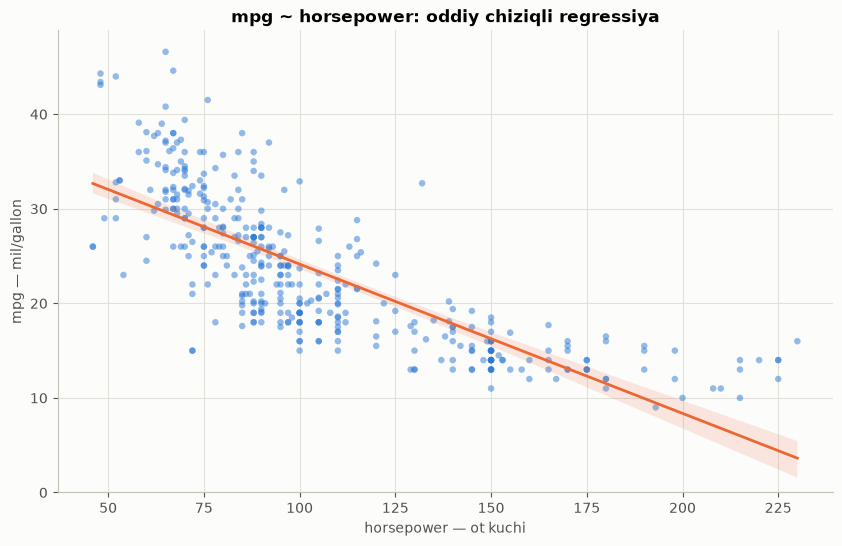

In [58]:
width = 10
height = 6
plt.figure(figsize=(width, height))
sns.regplot(x="horsepower", y="mpg", data=df, scatter_kws=NUQTA_USLUB, line_kws=CHIZIQ_USLUB)
plt.ylim(0,)
plt.title("mpg ~ horsepower: oddiy chiziqli regressiya")
plt.xlabel("horsepower — ot kuchi")
plt.ylabel("mpg — mil/gallon")
plt.show()

**Kuzatish:**
- Chiziq pastga tushadi → **manfiy** bogʻliqlik: ot kuchi oshsa, `mpg` kamayadi.
- Lekin nuqtalar **egri** boʻylab joylashgan: chap chetda (≤ 70 ot kuchi) va oʻng chetda (≥ 170) nuqtalar chiziqdan **yuqorida**, oʻrtada (90–110) esa **pastda**.

### 9.2. Residual plot (qoldiqlar grafigi)
**Nima uchun kerak:** model qayerda xato qilayotganini koʻrish.

**Formula:** har bir mashina uchun qoldiq $e = y - \hat{y}$ (7.1-boʻlimdagidek). Grafikda X oʻqida — ot kuchi, Y oʻqida — qoldiq.

**Qanday oʻqiladi:**
- nuqtalar 0 chizigʻi atrofida **tasodifiy** sochilgan → model yaxshi, chiziq toʻgʻri tanlangan;
- **egri shakl** (masalan, U harfi) → bogʻliqlik egri, toʻgʻri chiziq yetarli emas;
- **kenglik oʻzgaradi** (bir tomonda keng, boshqasida tor) → xato kattaligi X ga bogʻliq.

`lowess=True` — nuqtalar orqali silliq trend chizigʻini chizadi. Seaborn'ning yangi versiyalarida `x=` va `y=` ni nomi bilan yozish kerak (maʼruzadagi `sns.residplot(df['highway-mpg'], df['price'])` endi xato beradi).

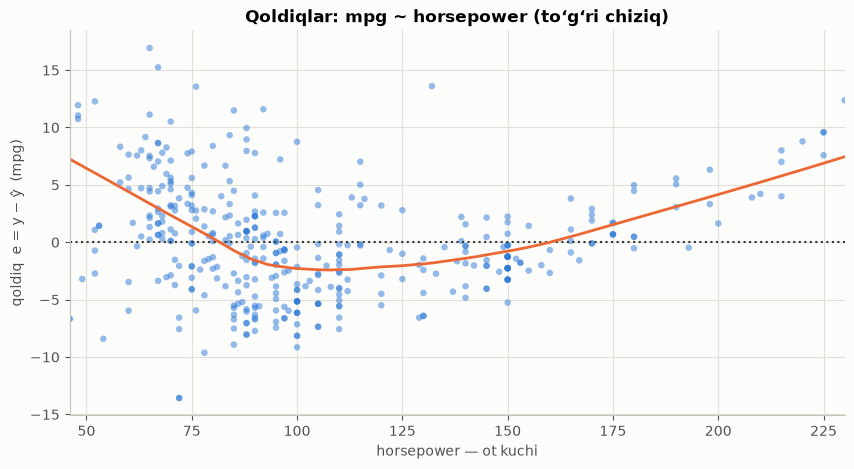

In [59]:
plt.figure(figsize=(width, 5))
sns.residplot(x="horsepower", y="mpg", data=df, lowess=True,
              scatter_kws=NUQTA_USLUB, line_kws=CHIZIQ_USLUB)
plt.title("Qoldiqlar: mpg ~ horsepower (toʻgʻri chiziq)")
plt.xlabel("horsepower — ot kuchi")
plt.ylabel("qoldiq  e = y − ŷ  (mpg)")
plt.show()

**Kuzatish:**
- Trend chizigʻi **U shaklida**: ≤ 70 ot kuchli mashinalarda qoldiqlar oʻrtacha **+3.7** (model kam bashorat qiladi), 90–110 da **−2.6** (koʻp bashorat qiladi), 170 dan yuqorida yana **+4.3**.
- Demak, toʻgʻri chiziq bu maʼlumotga toʻliq mos emas, **egri chiziq (polinom)** yaxshiroq boʻlishi mumkin (10-boʻlim). Spearman testi ham buni koʻrsatgan edi (5.3).
- Chap tomonda nuqtalar kengroq sochilgan → kam quvvatli mashinalarning `mpg` i juda turlicha.

### 9.3. Distribution plot (taqsimot grafigi)
**Nima uchun kerak:** koʻp chiziqli modelni (4 ta X) bitta tekis rasmda chizib boʻlmaydi. Shuning uchun **haqiqiy `mpg` lar taqsimotini** **bashorat qilingan `mpg` lar taqsimoti** bilan solishtirdim: ikki egri chiziq qanchalik ustma-ust tushsa, model shuncha yaxshi.

**Egri chiziq qanday chiziladi (KDE):** bu gistogrammaning silliq varianti. Har bir mashinaning `mpg` i ustiga kichkina "qoʻngʻiroq" qoʻyiladi va hamma qoʻngʻiroqlar qoʻshiladi. Mashinalar koʻp boʻlgan joyda egri chiziq baland. Egri chiziq ostidagi yuza doim 1 ga teng, shuning uchun Y oʻqi — mashinalar ulushi.

Maʼruzadagi `sns.distplot` funksiyasi eskirgan, uning oʻrniga xuddi shu ishni qiladigan `sns.kdeplot` ni ishlatdim.

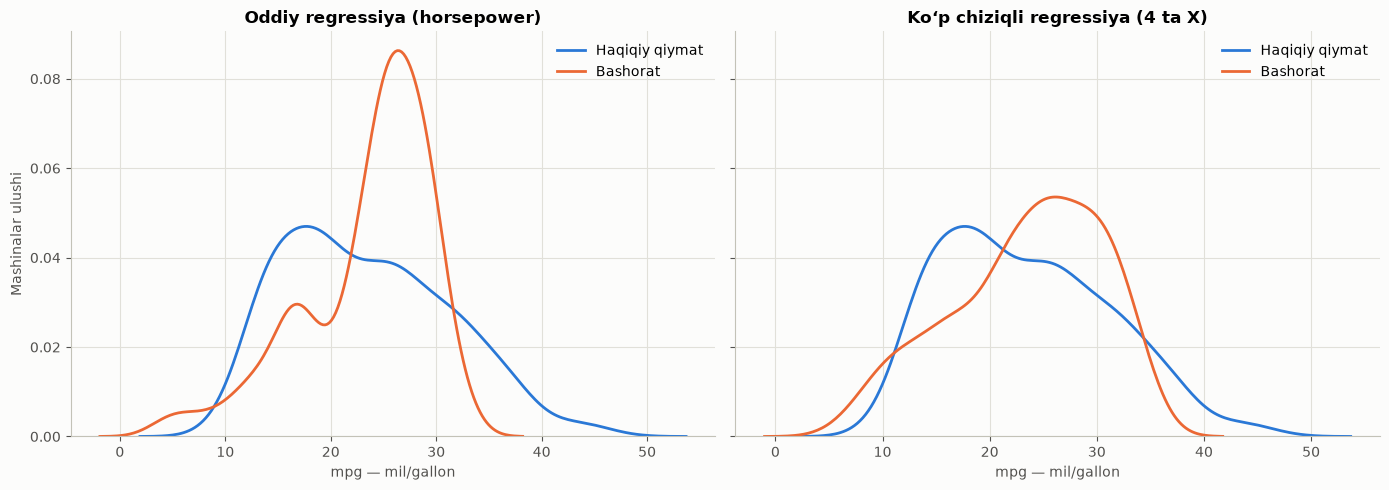

In [60]:
Y_hat_mlr = lm_mlr.predict(Z)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, bashorat, sarlavha in [(axes[0], Yhat, "Oddiy regressiya (horsepower)"),
                               (axes[1], Y_hat_mlr, "Koʻp chiziqli regressiya (4 ta X)")]:
    sns.kdeplot(Y, color=ASOSIY_RANG, linewidth=2, label="Haqiqiy qiymat", ax=ax)
    sns.kdeplot(bashorat, color=URGU_RANG, linewidth=2, label="Bashorat", ax=ax)
    ax.set_title(sarlavha)
    ax.set_xlabel("mpg — mil/gallon")
    ax.legend()
axes[0].set_ylabel("Mashinalar ulushi")
plt.tight_layout()
plt.show()

**Kuzatish:**
- **Chapda (bitta X):** bashorat egri chizigʻi tor va baland — model mashinalarning 44 % ini 25–30 mpg oraligʻiga qoʻyadi (haqiqatda ular 19 %). Eng katta bashorat 32.7 mpg, yaʼni 33 mpg dan tejamkor 52 ta mashinani model umuman "koʻrmaydi".
- **Oʻngda (4 ta X):** egri chiziqlar ancha yaqin. Lekin 15–20 mpg atrofida bashorat haqiqatdan kam, 38 mpg dan yuqori mashinalar ham yetarli bashorat qilinmaydi.
- Xulosa: koʻp chiziqli model yaxshiroq, lekin hali mukammal emas.

## 10. Polinomial regressiya

**Nima uchun kerak:** bogʻliqlik egri boʻlsa (9.2-boʻlimdagi U shakli), toʻgʻri chiziq oʻrniga **egri chiziq** oʻtkazish.

**Formulalar:**

| Tartib | Formula | Shakli |
|---|---|---|
| 1-tartib | $\hat{y} = a + b_1 x$ | toʻgʻri chiziq |
| 2-tartib | $\hat{y} = a + b_1 x + b_2 x^2$ | bir marta egilgan (parabola) |
| 3-tartib | $\hat{y} = a + b_1 x + b_2 x^2 + b_3 x^3$ | ikki marta egilishi mumkin |

(Maʼruza slaydida $b_1 x^2 + b_2 x^2$ deb yozilgan, menimcha bu xato: birinchi had $b_1 x$ boʻlishi kerak.)

**Soʻz bilan:** $x^2$ hadi chiziqni "egadi", $x^3$ — yana bir marta egish imkonini beradi.

**Qayerdan kelgan:** $x^2$ va $x^3$ ni oddiy yangi ustunlar deb qarasam, bu yana 8-boʻlimdagi koʻp chiziqli regressiya boʻlib qoladi. Koeffitsiyentlar oʻsha eng kichik kvadratlar usuli bilan topiladi.

### 10.1. Bitta X uchun: `np.polyfit`
Maʼruzadagidek 3-tartibli polinom qurdim:

In [61]:
x = df["horsepower"]
y = df["mpg"]

f = np.polyfit(x, y, 3)   # 3-tartibli polinom koeffitsiyentlari (eng katta darajadan boshlab)
p = np.poly1d(f)          # koeffitsiyentlardan funksiya yasadim: p(x)
print(p)

            3            2
-2.147e-06 x + 0.002079 x - 0.5689 x + 60.68


**Qoʻlda tekshirish:** 100 ot kuchli mashina uchun bashorat ($x = 100$). Har bir hadni alohida hisobladim:
- $x^3$ hadi: $-0.000002147 \times 100^3 = -0.000002147 \times 1\,000\,000 = -2.147$
- $x^2$ hadi: $0.002079 \times 100^2 = 0.002079 \times 10\,000 = 20.79$
- $x$ hadi: $-0.5689 \times 100 = -56.89$
- oʻzgarmas son: $60.68$

$$\hat{y} = -2.147 + 20.79 - 56.89 + 60.68 = 22.433$$

In [62]:
print("Polinom (3-tartib): p(100) =", round(p(100), 3))
print("Toʻgʻri chiziq:     ŷ(100) =", round(lm.intercept_ + lm.coef_[0] * 100, 3))

Polinom (3-tartib): p(100) = 22.443
Toʻgʻri chiziq:     ŷ(100) = 24.151


Kod 22.443 berdi, men qoʻlda 22.433 topdim — farq koeffitsiyentlarni yaxlitlaganimdan. Toʻgʻri chiziq shu mashina uchun 24.15 mpg beradi.

Polinom va toʻgʻri chiziqni bitta grafikda solishtirdim:

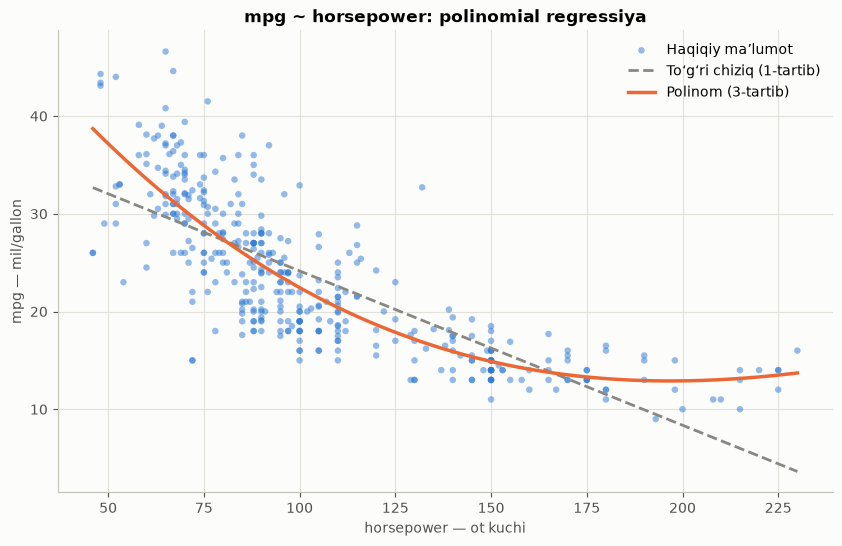

In [63]:
def PlotPolly(model, x, y):
    """Nuqtalar + toʻgʻri chiziq (lm) + polinom egri chizigʻi."""
    x_yangi = np.linspace(x.min(), x.max(), 200)   # silliq chizish uchun 200 ta nuqta

    plt.figure(figsize=(width, height))
    plt.scatter(x, y, label="Haqiqiy maʼlumot", **NUQTA_USLUB)
    plt.plot(x_yangi, lm.intercept_ + lm.coef_[0] * x_yangi,
             color=KULRANG, linewidth=2, linestyle="--", label="Toʻgʻri chiziq (1-tartib)")
    plt.plot(x_yangi, model(x_yangi), color=URGU_RANG, linewidth=2.5,
             label=f"Polinom ({model.order}-tartib)")
    plt.title("mpg ~ horsepower: polinomial regressiya")
    plt.xlabel("horsepower — ot kuchi")
    plt.ylabel("mpg — mil/gallon")
    plt.legend()
    plt.show()


PlotPolly(p, x, y)

**Kuzatish:** egri chiziq chap chetda nuqtalar bilan birga yuqoriga koʻtariladi va ~150 ot kuchidan keyin yassilanadi — nuqtalarga toʻgʻri chiziqdan ancha yaxshi mos keladi.

Polinom qoldiqlardagi U shaklni yoʻqotdimi? Qoldiqlarni ($e = y - \hat{y}$) ikkala model uchun hisoblab, yonma-yon chizdim:

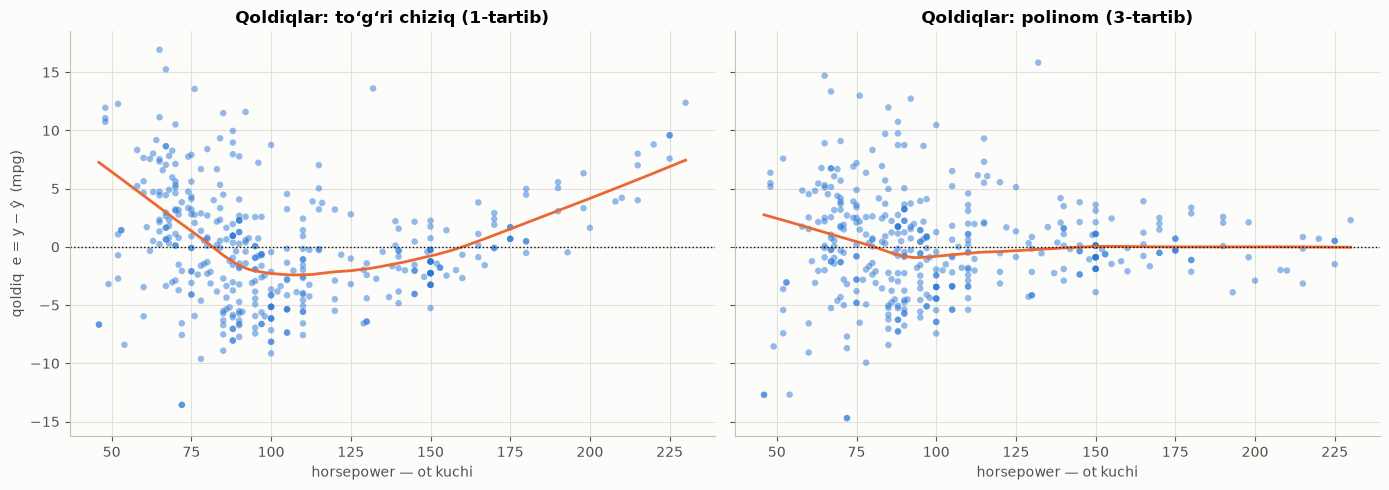

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, bashorat, sarlavha in [(axes[0], Yhat, "Qoldiqlar: toʻgʻri chiziq (1-tartib)"),
                               (axes[1], p(x), "Qoldiqlar: polinom (3-tartib)")]:
    qoldiq = y - bashorat                       # e = y − ŷ
    sns.regplot(x=x, y=qoldiq, lowess=True, ax=ax, scatter_kws=NUQTA_USLUB, line_kws=CHIZIQ_USLUB)
    ax.axhline(0, color="#0b0b0b", linestyle=":", linewidth=1)
    ax.set_title(sarlavha)
    ax.set_xlabel("horsepower — ot kuchi")
axes[0].set_ylabel("qoldiq  e = y − ŷ  (mpg)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

**Kuzatish:**
- Polinomda trend chizigʻi 0 atrofida deyarli tekis: ≤ 70 ot kuchida qoldiqlar oʻrtachasi +3.7 dan **+1.1** ga, 170 dan yuqorida +4.3 dan **−0.1** ga tushdi. U shakli deyarli yoʻqoldi.
- Chapda keng, oʻngda tor sochilish qoldi — kam quvvatli mashinalarning `mpg` ini faqat ot kuchiga qarab aniq aytib boʻlmaydi.

### 10.2. Bir nechta X uchun polinom: `PolynomialFeatures`
**Nima uchun kerak:** `np.polyfit` faqat **bitta** X bilan ishlaydi. Bir nechta X uchun `PolynomialFeatures` har bir X ning **kvadratini** va X larning **bir-biriga koʻpaytmasini** yangi ustun qilib qoʻshadi.

**Formula (2 ta X: $a$ va $b$, 2-daraja):**

$$[a,\ b] \ \longrightarrow\ [1,\ a,\ b,\ a^2,\ a \cdot b,\ b^2]$$

**Misol:** $a = 2,\ b = 3$ → $[1,\ 2,\ 3,\ 4,\ 6,\ 9]$. Tekshirdim:

In [65]:
pr_misol = PolynomialFeatures(degree=2)
pr_misol.fit_transform([[2, 3]])

array([[1., 2., 3., 4., 6., 9.]])

**Bizning 4 ta X uchun nechta ustun chiqadi** (sanab chiqdim):
- `1` — bitta ustun;
- X larning oʻzi — 4 ta;
- kvadratlar ($\text{hp}^2$, $\text{weight}^2$, ...) — 4 ta;
- juft koʻpaytmalar: hp·weight, hp·displacement, hp·year, weight·displacement, weight·year, displacement·year — 6 ta.

Jami: $1 + 4 + 4 + 6 = 15$ ta ustun.

In [66]:
pr = PolynomialFeatures(degree=2)
Z_pr = pr.fit_transform(Z)

print("Oldin:", Z.shape, "  ->  keyin:", Z_pr.shape)
pr.get_feature_names_out()

Oldin: (392, 4)   ->  keyin: (392, 15)


array(['1', 'horsepower', 'weight', 'displacement', 'model_year',
       'horsepower^2', 'horsepower weight', 'horsepower displacement',
       'horsepower model_year', 'weight^2', 'weight displacement',
       'weight model_year', 'displacement^2', 'displacement model_year',
       'model_year^2'], dtype=object)

## 11. Pipeline (konveyer)

**Nima uchun kerak:** model qurishdan oldin maʼlumot bir necha qadamdan oʻtadi: **standartlashtirish → polinom ustunlar → model**. Pipeline bu qadamlarni bitta zanjirga birlashtiradi: `fit` va `predict` ni bir marta chaqirsam, hamma qadamlar ketma-ket bajariladi.

**Formula:** zanjir — har bir qadam oldingisining natijasini oladi:

$$X \;\longrightarrow\; \text{standartlashtirish} \;\longrightarrow\; \text{polinom ustunlar} \;\longrightarrow\; \text{model} \;\longrightarrow\; \hat{y}$$

### 11.1. Standartlashtirish (`StandardScaler`)

**Nima uchun kerak:** X lar har xil birlikda: `weight` ~ 1600–5100 funt, `model_year` ~ 70–82. Ularni bitta shkalaga keltirish kerak — xuddi 100 ballik va 5 ballik baholarni solishtirish uchun ularni bir xil shkalaga oʻtkazgandek.

**Formula:**

$$z = \frac{x - \bar{x}}{\sigma}, \qquad \sigma = \sqrt{\frac{S_{xx}}{n}}$$

- $x - \bar{x}$ — oʻrtachadan chetlanish (0.2-boʻlim);
- $\sigma$ ("sigma") — **standart ogʻish**: qiymatlar oʻrtachadan odatda qancha uzoq;
- $z$ — **z-ball**.

**Soʻz bilan:** "mashina oʻrtachadan nechta $\sigma$ uzoqda".

**Qayerdan kelgan:**
- $x$ dan $\bar{x}$ ni ayirsam, yangi oʻrtacha **0** boʻladi (hamma qiymat bir xil miqdorga suriladi);
- $\sigma$ ga boʻlsam, tarqoqlik **1** ga keladi (hamma qiymat bir xil marta kichrayadi).
- Natijada har qanday ustun: oʻrtacha 0, standart ogʻish 1 — birliklar yoʻqoladi.

`StandardScaler` $\sigma$ ni hisoblashda $n$ ga boʻladi, pandas'ning `.std()` esa $n - 1$ ga — natijalar biroz farq qiladi.

**Qoʻlda hisoblash** (10 ta mashinaning ot kuchi; $\bar{x} = 93.1$, $S_{xx} = 19660.9$ — 0.2-boʻlimdan):

$$\sigma = \sqrt{\frac{19660.9}{10}} = \sqrt{1966.09} \approx 44.34$$

- Chevrolet Impala (220): $z = \dfrac{220 - 93.1}{44.34} = \dfrac{126.9}{44.34} \approx 2.862$ — oʻrtachadan 2.86 ta $\sigma$ yuqori;
- Toyota Corolla Tercel (60): $z = \dfrac{60 - 93.1}{44.34} = \dfrac{-33.1}{44.34} \approx -0.746$ — oʻrtachadan pastroq.

In [67]:
sigma = np.sqrt(S_xx / n)    # σ = √(S_xx / n)

scale = StandardScaler()
z_sklearn = scale.fit_transform(namuna[["horsepower"]]).ravel()   # .ravel() — natijani oddiy roʻyxat qiladi

print(f"σ (n ga boʻlib)     = {sigma:.3f}")
print(f"pandas .std() (n−1) = {x10.std():.3f}")

z_jadval = pd.DataFrame({
    "x (horsepower)": x10,
    "z (formula)": (x10 - x_ort) / sigma,
    "z (StandardScaler)": z_sklearn,
})
z_jadval.index = namuna["name"]
z_jadval.round(3)

σ (n ga boʻlib)     = 44.341
pandas .std() (n−1) = 46.739


,x (horsepower),z (formula),z (StandardScaler)
name,,,
datsun 210,65.0,-0.634,-0.634
chevrolet impala,220.0,2.862,2.862
ford pinto runabout,86.0,-0.160,-0.160
toyota corolla tercel,60.0,-0.746,-0.746
ford maverick,88.0,-0.115,-0.115
oldsmobile starfire sx,85.0,-0.183,-0.183
honda civic 1500 gl,67.0,-0.589,-0.589
nissan stanza xe,88.0,-0.115,-0.115
buick skylark,105.0,0.268,0.268


### 11.2. Standartlashtirilgan koeffitsiyentlar

**Nima uchun kerak:** 8-boʻlimda koeffitsiyentlarni solishtirib boʻlmadi — birliklar har xil edi. Standartlashtirgandan keyin har bir koeffitsiyent bir xil maʼnoni beradi: "**X 1 ta $\sigma$ ga oshsa, `mpg` qanchaga oʻzgaradi**".

**Formula:** $b_{\text{std}} = b \times \sigma$

**Qayerdan kelgan:** $X$ 1 ga oshsa, $\hat{y}$ $b$ ga oʻzgaradi. Demak, $X$ $\sigma$ ga oshsa, $\hat{y}$ $b \times \sigma$ ga oʻzgaradi. Masalan, `weight`: $b = -0.0066$, $\sigma = 848$ funt → $-0.0066 \times 848 = -5.59$.

In [68]:
pipe_std = Pipeline([("scale", StandardScaler()), ("model", LinearRegression())])
pipe_std.fit(Z, Y)

pd.DataFrame({
    "b (8-boʻlim)": lm_mlr.coef_,
    "σ": Z.std(ddof=0).to_numpy(),
    "b × σ (formula)": lm_mlr.coef_ * Z.std(ddof=0).to_numpy(),
    "pipeline koeffitsiyenti": pipe_std.named_steps["model"].coef_,    # qadamga nomi orqali murojaat
}, index=Z.columns)

,b (8-boʻlim),σ,b × σ (formula),pipeline koeffitsiyenti
horsepower,-0.0067,38.4420,-0.2573,-0.2573
weight,-0.0066,848.3184,-5.5908,-5.5908
displacement,0.0018,104.5104,0.1922,0.1922
model_year,0.7505,3.6790,2.7611,2.7611


**Kuzatish:** formula $b \times \sigma$ va pipeline bir xil natija berdi: `weight` −5.59, `model_year` +2.76, `horsepower` −0.26, `displacement` +0.19. Endi solishtirsa boʻladi: `mpg` ga eng katta taʼsir — **`weight`**, keyin **`model_year`**. Bu 8.1-boʻlimdagi t lar bilan mos keladi.

### 11.3. Toʻliq pipeline: standartlashtirish → polinom → regressiya
Maʼruzadagidek roʻyxat tuzdim: har bir qadamning **nomi** va **obʼyekti**. Roʻyxatni `Pipeline` ga berdim:

In [69]:
Input = [("scale", StandardScaler()),
         ("polynomial", PolynomialFeatures(include_bias=False)),
         ("model", LinearRegression())]

pipe = Pipeline(Input)
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('polynomial', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",False
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",2
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


- `PolynomialFeatures` ning darajasi koʻrsatilmasa — 2.
- `include_bias=False` — 1 lardan iborat ustun kerak emas, chunki `LinearRegression` $b_0$ ni oʻzi hisoblaydi.

In [70]:
pipe.fit(Z, Y)              # 1) standartlashtiradi  2) polinom ustunlar yasaydi  3) modelni oʻrgatadi
ypipe = pipe.predict(Z)     # bashoratda ham xuddi shu qadamlar avtomatik bajariladi

pd.DataFrame({
    "haqiqiy mpg": Y[0:4],
    "MLR bashorati": Y_hat_mlr[0:4],
    "Pipeline bashorati": ypipe[0:4],
}).round(2)

,haqiqiy mpg,MLR bashorati,Pipeline bashorati
0,18.0,15.53,14.91
1,15.0,14.12,14.49
2,18.0,15.86,15.13
3,16.0,15.85,15.26


**Kuzatish:** birinchi 4 ta mashinaga qarab qaysi model yaxshiroq ekanini aytib boʻlmaydi — buning uchun hamma 392 ta mashina boʻyicha oʻlchov kerak: MSE va R².

## 12. Modelni sonlar bilan baholash: MSE va R²

### 12.1. MSE — oʻrtacha kvadratik xato

**Nima uchun kerak:** model **oʻrtacha qancha xato** qilishini bitta son bilan aytish. Qancha **kichik** boʻlsa, shuncha yaxshi.

**Formula:**

$$MSE = \frac{\sum (y - \hat{y})^2}{n} = \frac{SSE}{n}, \qquad RMSE = \sqrt{MSE}$$

**Soʻz bilan:** har bir mashinaning xatosini ($e = y - \hat{y}$) kvadratga koʻtarib, oʻrtachasini olaman.

**Qayerdan kelgan:** bu 7-boʻlimda eng kichik qilgan $SSE$ ning oʻzi, faqat mashinalar soniga boʻlingan.
- **Nega kvadrat:** musbat va manfiy xatolar bir-birini yoʻqotmasin; katta xatolar koʻproq "jazolansin".
- **RMSE:** MSE ning birligi "mpg²" — tushunish qiyin. Ildizini olsam, xato oddiy mpg da chiqadi.

Maʼruzadagi misol: haqiqiy qiymat 150, bashorat 50 → xato 100 → kvadrati 10 000.

**Qoʻlda hisoblash** (7.1-boʻlimdagi qoldiqlar):

| Mashina | $e = y - \hat{y}$ | $e^2$ |
|---|---|---|
| datsun 210 | 0.163 | 0.027 |
| chevrolet impala | 3.637 | 13.229 |
| ford pinto runabout | −7.754 | 60.132 |
| toyota corolla tercel | 5.777 | 33.374 |
| ford maverick | −10.480 | 109.830 |
| oldsmobile starfire sx | −5.092 | 25.926 |
| honda civic 1500 gl | 13.238 | 175.238 |
| nissan stanza xe | 7.520 | 56.551 |
| buick skylark | −5.647 | 31.885 |
| mercedes-benz 240d | −1.362 | 1.856 |
| **Σ** | | **508.05** |

$$MSE = \frac{508.05}{10} = 50.80, \qquad RMSE = \sqrt{50.80} \approx 7.13 \text{ mpg}$$

Yaʼni bu 10 ta mashinada model oʻrtacha ~7 mpg ga adashadi.

### 12.2. R² — determinatsiya koeffitsiyenti

**Nima uchun kerak:** model **oʻrtachani aytishdan qanchalik yaxshi** ekanini 0 dan 1 gacha son bilan aytish.

**Formula:**

$$R^2 = 1 - \frac{SSE}{SST}$$

- $SSE = \sum (y - \hat{y})^2$ — **mening modelimning** xatosi (508.05);
- $SST = \sum (y - \bar{y})^2$ — **eng oddiy "model"** ning xatosi: hech narsa bilmasdan, har doim oʻrtacha $\bar{y} = 27.78$ ni aytsam. Bu 0.2-boʻlimdagi $S_{yy} = 878.416$ ning oʻzi.

**Soʻz bilan:** "modelim oʻrtachaga nisbatan xatoning qancha qismini yoʻqotdi".

**Qayerdan kelgan:**
- $SSE / SST$ — xatoning **qolgan** ulushi;
- $1 - (\text{qolgan ulush})$ — **yoʻqotilgan** (tushuntirilgan) ulush.
- $R^2 = 1$ — model hamma nuqtani aniq topadi; $R^2 = 0$ — model oʻrtachani aytishdan yaxshi emas.

(Maʼruza slaydida formulada "1 −" tushib qolgan.)

**Qoʻlda hisoblash:**

$$R^2 = 1 - \frac{508.05}{878.42} = 1 - 0.578 = 0.422$$

Maʼnosi: 10 ta mashinada ot kuchi `mpg` dagi farqlarning **~42 %** ini tushuntiradi.

**Qiziq fakt:** bitta X boʻlganda $R^2 = r^2$: $(-0.649)^2 = 0.421$ ✓. 2-boʻlimdagi $1 - r^2$ — "tushuntirilmagan qism" — shundan kelib chiqadi.

In [71]:
yhat10 = lm_10.predict(namuna[["horsepower"]])

SSE = ((y10 - yhat10) ** 2).sum()          # modelim xatosi
SST = ((y10 - y_ort) ** 2).sum()           # "har doim oʻrtachani aytish" xatosi = S_yy

print(f"SSE = {SSE:.3f},   SST = {SST:.3f}  (S_yy = {S_yy:.3f})")
print(f"MSE:  qoʻlda = {SSE / n:.3f},   sklearn = {mean_squared_error(y10, yhat10):.3f}")
print(f"RMSE: {np.sqrt(SSE / n):.3f} mpg")
print(f"R²:   qoʻlda = {1 - SSE / SST:.4f},   r2_score = {r2_score(y10, yhat10):.4f},   r² = {r ** 2:.4f}")

SSE = 508.047,   SST = 878.416  (S_yy = 878.416)
MSE:  qoʻlda = 50.805,   sklearn = 50.805
RMSE: 7.128 mpg
R²:   qoʻlda = 0.4216,   r2_score = 0.4216,   r² = 0.4216


### 12.3. Butun toʻplamda
Maʼruzadagi kod: `mean_squared_error(haqiqiy, bashorat)` va `lm.score(X, Y)` (R² ni beradi).

In [72]:
mse = mean_squared_error(df["mpg"], Yhat)
print("The mean square error of mpg and predicted value is:", mse)
print("The R-square is:", lm.score(X, Y))

The mean square error of mpg and predicted value is: 23.943662938603104
The R-square is: 0.6059482578894351


**Kuzatish:** MSE ≈ 23.94 (RMSE ≈ 4.89 mpg), R² ≈ 0.606 → ot kuchi `mpg` dagi farqlarning **60.6 %** ini tushuntiradi.

Endi barcha modellarni bitta jadvalda solishtirdim:

In [73]:
modellar = {
    "SLR: horsepower": Yhat,
    "SLR: weight": lm_w.predict(df[["weight"]]),
    "Polinom (3-tartib): horsepower": p(x),
    "MLR: 4 ta X": Y_hat_mlr,
    "Pipeline: 4 ta X, 2-daraja": ypipe,
}

taqqoslash = pd.DataFrame({
    nom: {"MSE": mean_squared_error(Y, bashorat),
          "RMSE (mpg)": np.sqrt(mean_squared_error(Y, bashorat)),
          "R²": r2_score(Y, bashorat)}
    for nom, bashorat in modellar.items()
}).T
taqqoslash.sort_values("R²")

,MSE,RMSE (mpg),R²
SLR: horsepower,23.9437,4.8932,0.6059
Polinom (3-tartib): horsepower,18.9450,4.3526,0.6882
SLR: weight,18.6766,4.3216,0.6926
MLR: 4 ta X,11.6435,3.4123,0.8084
"Pipeline: 4 ta X, 2-daraja",7.4213,2.7242,0.8779


**Kuzatish:**
- Ot kuchi bilan: toʻgʻri chiziq R² = 0.606, polinom — **0.688**. Egri chiziq xatoni 4.89 dan 4.35 mpg ga kamaytirdi.
- `weight` yolgʻiz oʻzi (R² = 0.693) ot kuchi polinomidan ham sal yaxshi.
- 4 ta X: MLR — **0.808** (xato 3.41 mpg), pipeline — **0.878** (xato 2.72 mpg) — eng yaxshi natija.

### 12.4. Polinom darajasini tanlash
Daraja qancha yuqori boʻlsa, model shuncha yaxshimi — tekshirdim:

In [74]:
natijalar = []
for daraja in range(1, 6):
    p_d = np.poly1d(np.polyfit(x, y, daraja))
    natijalar.append({"daraja": daraja,
                      "MSE": mean_squared_error(y, p_d(x)),
                      "R²": r2_score(y, p_d(x))})

pd.DataFrame(natijalar).set_index("daraja")

,MSE,R²
daraja,,
1,23.9437,0.6059
2,18.9848,0.6876
3,18.9450,0.6882
4,18.8763,0.6893
5,18.4270,0.6967


**Kuzatish:**
- 1 → 2-daraja: R² 0.606 → 0.688 — katta sakrash. 2 → 5-daraja: atigi 0.688 → 0.697.
- Daraja oshgani sari R² **shu maʼlumotda** doim oshadi: egri chiziq nuqtalarga tobora yaqinroq egila oladi. Lekin bu yangi mashinalarda ham yaxshi ishlaydi degani emas — model nuqtalarni "yodlab olishi" mumkin (**overfitting**).
- Shuning uchun kichik yaxshilanish uchun murakkab modelni tanlamayman: bu yerda 2-daraja yetarli.

## 13. Bashorat qilish va qaror qabul qilish

Model qurildi, endi undan foydalanaman. Lekin har bir natijani **mantiqqa** tekshirish kerak: manfiy, juda katta yoki juda kichik qiymat — ogohlantiruvchi belgi.

### 13.1. Bitta mashina uchun bashorat
Maʼruzada: "100 km ga 10 litr yoqilgʻi sarflaydigan mashina narxi qancha?" Mening savolim: **100 ot kuchli mashina necha mpg yuradi?**

**mpg ni litr/100 km ga oʻtkazish formulasi:** $\text{L/100 km} = \dfrac{235.21}{\text{mpg}}$

**Qayerdan kelgan:**
- 100 km $= 100 / 1.609 = 62.14$ mil;
- mashina 1 gallonda "mpg" mil yursa, 62.14 milga $62.14 / \text{mpg}$ gallon kerak;
- 1 gallon $= 3.785$ litr → $\dfrac{62.14 \times 3.785}{\text{mpg}} = \dfrac{235.21}{\text{mpg}}$ litr.

Yangi qiymatni oʻrgatishdagi ustun nomi bilan jadval qilib berdim (oddiy `[[100]]` bersam, sklearn ogohlantirish chiqaradi).

In [75]:
yangi_mashina = pd.DataFrame({"horsepower": [100]})
bashorat = lm.predict(yangi_mashina)[0]

print(f"100 ot kuchli mashina: {bashorat:.2f} mpg")
print(f"Litr/100 km da: 235.21 / {bashorat:.2f} ≈ {235.21 / bashorat:.1f} litr/100 km")
print(f"Koeffitsiyent: {lm.coef_[0]:.4f}  ->  +10 ot kuchi = {lm.coef_[0] * 10:.2f} mpg")

100 ot kuchli mashina: 24.15 mpg
Litr/100 km da: 235.21 / 24.15 ≈ 9.7 litr/100 km
Koeffitsiyent: -0.1578  ->  +10 ot kuchi = -1.58 mpg


**Kuzatish:** 24.15 mpg ≈ 9.7 litr/100 km — mantiqiy: toʻplamda `mpg` 9 dan 46.6 gacha, oʻrtachasi 23.4. Koeffitsiyent ham mantiqiy: ot kuchi 10 ga oshsa, `mpg` 1.6 ga kamayadi.

Koʻp chiziqli model va pipeline bilan ham bashorat qildim — 1980-yilgi, 3000 funtli, 200 kub dyuymli, 100 ot kuchli mashina:

In [76]:
yangi_mashina_4 = pd.DataFrame({"horsepower": [100], "weight": [3000],
                                "displacement": [200], "model_year": [80]})

print("MLR:     ", round(lm_mlr.predict(yangi_mashina_4)[0], 2), "mpg")
print("Pipeline:", round(pipe.predict(yangi_mashina_4)[0], 2), "mpg")

MLR:      26.36 mpg
Pipeline: 24.79 mpg


### 13.2. Mantiqsiz bashoratlar: maʼlumot oraligʻidan tashqariga chiqish
Maʼruzada 1 dan 100 gacha qiymatlar uchun bashorat qilinganda narx manfiy chiqqan. Men ham 1 dan 400 gacha ot kuchi uchun bashorat qildim. Toʻplamda esa ot kuchi faqat 46 dan 230 gacha.

`np.arange(1, 401, 1)` → 1, 2, 3, ..., 400 (oxirgi son — 401 — kirmaydi).

**Qachon mpg manfiy boʻladi:** $\hat{y} = 0$ boʻladigan nuqtani topdim:

$$39.94 - 0.158 \cdot x = 0 \quad \Rightarrow \quad x = \frac{39.94}{0.158} \approx 253 \text{ ot kuchi}$$

In [77]:
new_input = pd.DataFrame({"horsepower": np.arange(1, 401, 1)})
yhat_yangi = lm.predict(new_input)

print("Birinchi 5 ta bashorat:", yhat_yangi[0:5].round(2))
print("Manfiy mpg bashoratlari soni:", (yhat_yangi < 0).sum(), "ta")
print(f"ŷ = 0 boʻladigan nuqta: x = b0 / |b1| = {lm.intercept_:.2f} / {abs(lm.coef_[0]):.4f} = {-lm.intercept_ / lm.coef_[0]:.1f} ot kuchi")
print("Toʻplamdagi ot kuchi oraligʻi:", df["horsepower"].min(), "–", df["horsepower"].max())

Birinchi 5 ta bashorat: [39.78 39.62 39.46 39.3  39.15]
Manfiy mpg bashoratlari soni: 147 ta
ŷ = 0 boʻladigan nuqta: x = b0 / |b1| = 39.94 / 0.1578 = 253.0 ot kuchi
Toʻplamdagi ot kuchi oraligʻi: 46.0 – 230.0


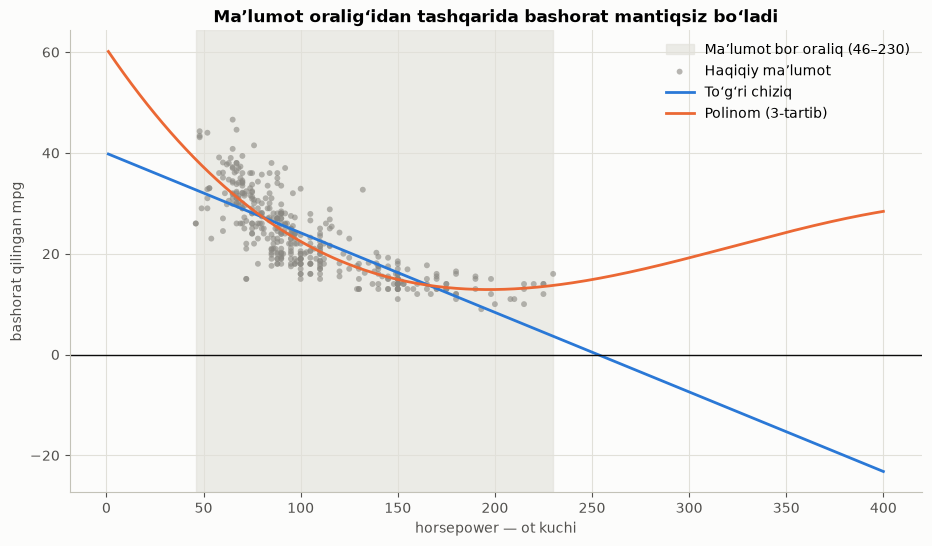

In [78]:
hp = new_input["horsepower"]

fig, ax = plt.subplots(figsize=(11, 6))
ax.axvspan(df["horsepower"].min(), df["horsepower"].max(), color="#e1e0d9", alpha=0.6,
           label="Maʼlumot bor oraliq (46–230)")
ax.scatter(df["horsepower"], df["mpg"], color=KULRANG, alpha=0.6, s=18, edgecolor="none", label="Haqiqiy maʼlumot")
ax.plot(hp, yhat_yangi, color=ASOSIY_RANG, linewidth=2, label="Toʻgʻri chiziq")
ax.plot(hp, p(hp), color=URGU_RANG, linewidth=2, label="Polinom (3-tartib)")
ax.axhline(0, color="#0b0b0b", linewidth=1)
ax.set_title("Maʼlumot oraligʻidan tashqarida bashorat mantiqsiz boʻladi")
ax.set_xlabel("horsepower — ot kuchi")
ax.set_ylabel("bashorat qilingan mpg")
ax.legend(loc="upper right")
plt.show()

**Kuzatish:**
- Toʻgʻri chiziq **253 ot kuchidan** keyin manfiy `mpg` beradi (147 ta bashorat) — bunday boʻlishi mumkin emas.
- Polinom ~197 ot kuchidan keyin yuqoriga qayriladi: 400 ot kuchli mashina uchun 28.4 mpg, yaʼni 150 ot kuchli mashinadan (14.9 mpg) ham tejamkor! Bu ham mantiqsiz.
- 1 ot kuchi uchun toʻgʻri chiziq 39.8 mpg, polinom 60.1 mpg beradi — bunday mashina yoʻq.
- **Xulosa:** model faqat oʻzi oʻrgangan oraliqda (46–230 ot kuchi) ishonchli. Oraliqdan tashqarida bashorat qilish (**ekstrapolyatsiya**) xavfli.

## 14. Xulosa

### Barcha formulalar bir joyda

| Formula | Nimani hisoblaydi | Bizdagi qiymat (10 ta mashina) |
|---|---|---|
| $\bar{x} = \sum x / n$ | oʻrtacha | $\bar{x} = 93.1$, $\bar{y} = 27.78$ |
| $S_{xx} = \sum (x - \bar{x})^2$ | tarqoqlik | $S_{xx} = 19660.9$, $S_{yy} = 878.416$ |
| $S_{xy} = \sum (x - \bar{x})(y - \bar{y})$ | birga oʻzgarish | $-2698.48$ |
| $r = S_{xy} / \sqrt{S_{xx} S_{yy}}$ | bogʻliqlik kuchi (−1 … +1) | $-0.649$ |
| $t = r\sqrt{n-2} / \sqrt{1-r^2}$ | signal / shovqin | $-2.415$ |
| $df = n - 2$ | erkinlik darajasi | 8 |
| $p = 2 \cdot P(T \geq \lvert t \rvert)$ | tasodif ehtimoli | 0.042 |
| $F = \dfrac{SS_B/(k-1)}{SS_W/(N-k)}$ | guruhlar orasidagi / ichidagi farq | 18.51 |
| $E = \text{qator} \times \text{ustun} / N$ | bogʻliqlik yoʻq boʻlsa kutilgan son | 124.4 (AQSH, 4 silindr) |
| $\chi^2 = \sum (O - E)^2 / E$ | haqiqat va kutilgan farqi | 133.5 (392 ta mashina) |
| $t = (\bar{x}_1 - \bar{x}_2) / (s_p\sqrt{1/n_1 + 1/n_2})$ | ikki guruh farqi / shovqin | 6.06 |
| $W$ | normallik (1 ga yaqin — normal) | 0.639 |
| $\rho_s = 1 - 6\sum d^2 / (n(n^2-1))$ | oʻrinlar boʻyicha korrelyatsiya | $-0.752$ |
| $H$ | oʻrinlar boʻyicha ANOVA | 7.364 |
| $b_1 = S_{xy} / S_{xx}$, $b_0 = \bar{y} - b_1\bar{x}$ | chiziq qiyaligi va kesishishi | $-0.137$; 40.56 |
| $e = y - \hat{y}$ | qoldiq (xato) | Impala: +3.64 |
| $z = (x - \bar{x}) / \sigma$ | oʻrtachadan nechta σ uzoq | Impala: 2.86 |
| $MSE = SSE / n$, $RMSE = \sqrt{MSE}$ | oʻrtacha xato | 50.80; 7.13 mpg |
| $R^2 = 1 - SSE / SST$ | tushuntirilgan ulush | 0.422 |

### Natijalar

**I qism:** barcha testlar (Pearson, Spearman, ANOVA, Kruskal–Wallis, t-test, χ²) kuchli dalil berdi: `mpg` ot kuchiga va ishlab chiqarilgan joyga bogʻliq, kelib chiqish silindrlar soni bilan bogʻliq. `mpg` normal taqsimlanmagan, lekin normallik talab qilmaydigan testlar ham xuddi shu xulosani berdi.

**II qism:**

| Model | X | R² | RMSE (mpg) |
|---|---|---|---|
| Toʻgʻri chiziq | `horsepower` | 0.606 | 4.89 |
| Polinom (3-tartib) | `horsepower` | 0.688 | 4.35 |
| Toʻgʻri chiziq | `weight` | 0.693 | 4.32 |
| Koʻp chiziqli | 4 ta | 0.808 | 3.41 |
| Pipeline | 4 ta | **0.878** | **2.72** |

1. Ot kuchi va `mpg` orasidagi bogʻliqlik egri — buni residual plot va Spearman koʻrsatdi, polinom uni yaxshiroq ifodaladi.
2. `mpg` ga eng kuchli taʼsir — ogʻirlik, keyin yil. Ot kuchi va dvigatel hajmi ogʻirlik bilan deyarli bir xil maʼlumot beradi (multikollinearlik).
3. Murakkab model **shu maʼlumotda** doim yaxshiroq natija beradi. U yangi mashinalarda ham yaxshimi — buni bilish uchun maʼlumotni oʻrgatish (train) va sinov (test) qismlariga boʻlish kerak. Bu keyingi mavzu.
4. Bashoratni har doim mantiqqa tekshirish kerak: model faqat maʼlumot oraligʻida ishonchli.